# 03 — Pressure: Stay or Go?

PFF pass-rush micro-analysis. This notebook works directly off `pffScoutingData.csv` and is **independent of Sid's `route_features.parquet`** handoff — it never reads any route-feature parquet. Shared constants are imported from `src/config.py` by their actual names (config is Sid-owned and is not modified here).

In [1]:
# --- imports & reliable project-relative paths ---
import sys
from pathlib import Path

# Locate project root robustly whether cwd is repo root or notebooks/
for _p in [Path.cwd(), *Path.cwd().parents]:
    if (_p / 'src' / 'config.py').exists():
        sys.path.insert(0, str(_p / 'src'))
        _ROOT = _p
        break
else:
    raise SystemExit('Could not locate src/config.py from cwd.')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Shared constants imported by their actual names (Sid's config, unmodified).
from config import (
    DATA_DIR, ROOT, TE_RB_POSITIONS, RB_POSITIONS,
    END_EVENTS, NO_THROW_EVENTS, FPS,
)
print('project root:', ROOT)


project root: C:\Users\isaac\CodingProjects\NYUDataBowl


## Input checks

In [2]:
PFF_PATH = DATA_DIR / 'pffScoutingData.csv'
assert PFF_PATH.exists(), f'Missing required input: {PFF_PATH}'
print('PFF scouting data:', PFF_PATH)


PFF scouting data: C:\Users\isaac\CodingProjects\NYUDataBowl\data\pffScoutingData.csv


## Load PFF scouting data

In [3]:
pff = pd.read_csv(PFF_PATH, dtype={'gameId': 'Int64', 'playId': 'Int64', 'nflId': 'Int64'})
print('rows:', len(pff))
print('columns:', list(pff.columns))
pff['pff_role'].value_counts(dropna=False)


rows: 188254
columns: ['gameId', 'playId', 'nflId', 'pff_role', 'pff_positionLinedUp', 'pff_hit', 'pff_hurry', 'pff_sack', 'pff_beatenByDefender', 'pff_hitAllowed', 'pff_hurryAllowed', 'pff_sackAllowed', 'pff_nflIdBlockedPlayer', 'pff_blockType', 'pff_backFieldBlock']


pff_role
Coverage      57765
Pass Block    46057
Pass Route    39513
Pass Rush     36362
Pass           8557
Name: count, dtype: int64

## Pass-rushers per play

Count distinct pass-rushers per `(gameId, playId)`. This is the denominator for any 'pressure vs. extra rusher' analysis. (Earlier inspection conflated the `Pass` role count — one QB per play — with the `Pass Rush` rows; they are not the same.)

In [4]:
pr = pff[pff['pff_role'] == 'Pass Rush'].copy()
print('Pass Rush rows:', len(pr))
print('unique plays with pass rush:', pr.groupby(['gameId','playId']).ngroups)
print('duplicate (gameId,playId,nflId):', int(pr.duplicated(['gameId','playId','nflId']).sum()))
print('missing nflId:', int(pr['nflId'].isna().sum()))

rusher_counts = (pr.drop_duplicates(['gameId','playId','nflId'])
                   .groupby(['gameId','playId'])['nflId'].nunique())
dist = rusher_counts.value_counts().sort_index()
print('--- rusher-count distribution ---')
print(dist.to_string())
print('plays with >=5 rushers:', int((rusher_counts >= 5).sum()))


Pass Rush rows: 36362
unique plays with pass rush: 8556
duplicate (gameId,playId,nflId): 0
missing nflId: 0
--- rusher-count distribution ---
nflId
1       2
2      16
3     420
4    6011
5    1689
6     348
7      69
8       1
plays with >=5 rushers: 2107


## Rusher-count distribution (figure)

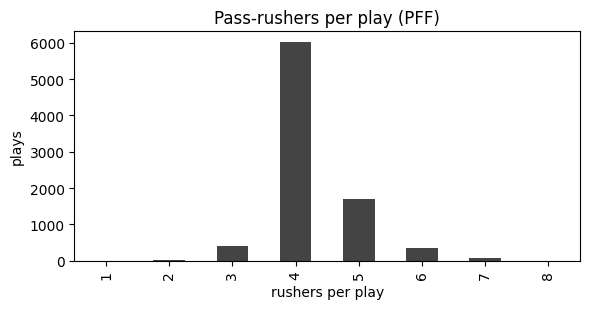

saved: C:\Users\isaac\CodingProjects\NYUDataBowl\figures\rushers_per_play.png


In [5]:
fig, ax = plt.subplots(figsize=(6,3.2))
dist.plot.bar(ax=ax, color='#444')
ax.set_xlabel('rushers per play')
ax.set_ylabel('plays')
ax.set_title('Pass-rushers per play (PFF)')
plt.tight_layout()
out = ROOT / 'figures' / 'rushers_per_play.png'
out.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(out, dpi=120)
plt.show()
print('saved:', out)


## Pressure production by rusher count

Exploratory only — share of plays with any hit/hurry/sack, split by number of rushers. Not a final result.

In [6]:
prx = pr.groupby(['gameId','playId']).agg(
    n_rushers=('nflId', 'nunique'),
    any_hit=('pff_hit', lambda s: int(s.fillna(0).gt(0).any())),
    any_hurry=('pff_hurry', lambda s: int(s.fillna(0).gt(0).any())),
    any_sack=('pff_sack', lambda s: int(s.fillna(0).gt(0).any())),
).reset_index()
prx['any_pressure'] = prx[['any_hit','any_hurry','any_sack']].max(axis=1)
tbl = prx.groupby('n_rushers')['any_pressure'].agg(['count','mean']).rename(
    columns={'count':'plays','mean':'pressure_rate'})
print(tbl.to_string())


           plays  pressure_rate
n_rushers                      
1              2       0.000000
2             16       0.062500
3            420       0.230952
4           6011       0.346531
5           1689       0.462996
6            348       0.482759
7             69       0.652174
8              1       1.000000


## Chip-benefit: does chipping reduce a rusher's pressure?

Uses only `pffScoutingData.csv`, `players.csv`, `plays.csv` (no tracking, no route-feature parquet). Shared constants imported by their actual names from `src/config` (`TE_RB_POSITIONS`, `RB_POSITIONS`, `N_BOOTSTRAP`, `RANDOM_SEED`).

- **Traditional dropbacks** only (`dropBackType == 'TRADITIONAL'`).
- **Qualifying chipper**: `pff_role == 'Pass Route'`, `pff_blockType == 'CH'`, `officialPosition` in `TE_RB_POSITIONS` (TE/RB/FB).
- **Rusher**: `pff_role == 'Pass Rush'`.
- **Rusher pressure**: `pff_hit == 1` OR `pff_hurry == 1` OR `pff_sack == 1`.
- **Matchup field** linking a chipper to the specific defender: `pff_nflIdBlockedPlayer`.

In [7]:
# --- chip-benefit section: load PFF/players/plays + validated MANY-TO-ONE joins ---
import sys
from pathlib import Path
import numpy as np
import pandas as pd

# shared constants by actual names (idempotent; also set by the setup cell)
for _p in [Path.cwd(), *Path.cwd().parents]:
    if (_p / 'src' / 'config.py').exists():
        sys.path.insert(0, str(_p / 'src')); break
from config import (DATA_DIR, ROOT, TE_RB_POSITIONS, RB_POSITIONS,
                    N_BOOTSTRAP, RANDOM_SEED)

pff = pd.read_csv(DATA_DIR / 'pffScoutingData.csv')
players = pd.read_csv(DATA_DIR / 'players.csv')
plays = pd.read_csv(DATA_DIR / 'plays.csv')

# Join shape: pff is the LEFT (many) side; players and plays are the RIGHT (one)
# sides. These are MANY-TO-ONE joins, not 1:1 — many pff rows share an nflId
# (one per player-play) and many share a (gameId,playId) (one per on-field player).
# What guarantees no row multiplication is that the RIGHT-side keys are unique:
assert players['nflId'].is_unique, 'players.nflId must be unique for many-to-one'
assert plays.duplicated(['gameId','playId']).sum() == 0, 'plays key must be unique'
assert pff.duplicated(['gameId','playId','nflId']).sum() == 0, 'pff key sanity'
print('join shape pff->players: many-to-one | max pff rows per nflId =',
      int(pff.groupby('nflId').size().max()))
print('join shape pff->plays:   many-to-one | max pff rows per play  =',
      int(pff.groupby(['gameId','playId']).size().max()))

n0 = len(pff)
pff = pff.merge(players[['nflId','officialPosition','displayName']], on='nflId', how='left')
pff = pff.merge(plays[['gameId','playId','down','yardsToGo','dropBackType']],
               on=['gameId','playId'], how='left')
# merge-coverage checks (how='left' keeps all pff rows; verify counts + match rates)
assert len(pff) == n0, 'join multiplied rows'
assert pff['officialPosition'].isna().sum() == 0, 'officialPosition missing after players join'
# dropBackType is NaN on 11,616 rows (SCRAMBLE/UNKNOWN/unlabeled plays); the
# TRADITIONAL filter downstream handles it, so it is reported, not asserted away.
assert pff['down'].isna().sum() == 0 and pff['yardsToGo'].isna().sum() == 0, 'down/distance missing'
print('rows after joins:', len(pff), '(unchanged from', n0, ')')
print('players-join match rate:', round(1 - pff['officialPosition'].isna().mean(), 6))
print('plays-join dropBackType NaN rows (SCRAMBLE/UNKNOWN/unlabeled):',
      int(pff['dropBackType'].isna().sum()))

join shape pff->players: many-to-one | max pff rows per nflId = 339
join shape pff->plays:   many-to-one | max pff rows per play  = 22
rows after joins: 188254 (unchanged from 188254 )
players-join match rate: 1.0
plays-join dropBackType NaN rows (SCRAMBLE/UNKNOWN/unlabeled): 11616


### Inspected label values (before selecting columns)

In [8]:
# role distribution + rusher pressure-flag MISSINGNESS audit
# Rule: any observed 1 => pressure; all three observed 0 => no pressure;
# otherwise (>=1 flag NaN and no observed 1) => UNKNOWN (excluded from rates).
print('pff_role:\n', pff['pff_role'].value_counts().to_string())
flags = ['pff_hit','pff_hurry','pff_sack']
pr_all = pff[pff['pff_role'] == 'Pass Rush']
for c in flags:
    print(f'  {c}: NaN={int(pr_all[c].isna().sum())} 1={int((pr_all[c]==1).sum())} 0={int((pr_all[c]==0).sum())}')
n_nan = pr_all[flags].isna().sum(axis=1)
print('  flags-NaN-per-row distribution (0=fully observed .. 3=all NaN):')
print('   ', n_nan.value_counts().sort_index().to_dict())
any1 = (pr_all[flags] == 1).any(axis=1)
all0_obs = (~pr_all[flags].isna()).all(axis=1) & ~any1
partial_unknown = (n_nan.between(1, 2)) & ~any1
all_nan = n_nan.eq(3)
print('  -> pressure (any observed 1):', int(any1.sum()))
print('  -> no pressure (all three observed 0):', int(all0_obs.sum()))
print('  -> UNKNOWN, partial-missing no observed 1:', int(partial_unknown.sum()))
print('  -> UNKNOWN, all flags NaN:', int(all_nan.sum()))
print('  actual missingness: flags are fully observed on every Pass Rush row'
      if int(n_nan.sum()) == 0 else '  actual missingness: some flags are NaN (see above)')

# --- chip-link reconciliation: FULL qualifying sample vs TRADITIONAL dropbacks ---
# Explains the earlier 18-vs-8 discrepancy: 18 unresolved links exist across ALL
# dropback types; restricting to TRADITIONAL (the analysis sample) leaves 8.
_role_by_key = pff.set_index(['gameId','playId','nflId'])['pff_role']

def reconcile_chip_links(df, label):
    chk = df[(df['pff_role']=='Pass Route') & (df['pff_blockType']=='CH')
             & (df['officialPosition'].isin(TE_RB_POSITIONS))].copy()
    blk = chk['pff_nflIdBlockedPlayer']
    n_missing = int(blk.isna().sum())           # missing/invalid target id
    links = chk.loc[blk.notna(), ['gameId','playId']].copy()
    links['blocked_id'] = blk[blk.notna()].astype('int64').values
    tgt_role = links.set_index(['gameId','playId','blocked_id']).index.map(_role_by_key)
    is_pr = (tgt_role == 'Pass Rush')
    is_cov = (tgt_role == 'Coverage')
    not_found = pd.isna(tgt_role)                 # id not present as a pff row on the play
    n_pr, n_cov = int(is_pr.sum()), int(is_cov.sum())
    n_other = int((~is_pr & ~is_cov & ~not_found).sum())
    n_nf = int(not_found.sum())
    uniq_plays = chk[['gameId','playId']].drop_duplicates().shape[0]
    print(f'\n[{label}] chipper rows={len(chk)} | unique plays={uniq_plays}')
    print(f'    chipper positions: {chk["officialPosition"].value_counts().to_dict()}')
    print(f'    matched Pass Rush target: {n_pr}')
    print(f'    matched Coverage target : {n_cov}')
    print(f'    other-role target       : {n_other}')
    print(f'    missing/invalid target  : {n_missing} (NaN id) + {n_nf} (id not on play) '
          f'= {n_missing + n_nf}')
    unresolved_plays = links.loc[~is_pr, ['gameId','playId']].drop_duplicates()
    print(f'    unresolved links (target not a Pass Rush): {int((~is_pr).sum()) + n_missing} '
          f'| affecting {unresolved_plays.shape[0]} unique plays')
    return unresolved_plays

reconcile_chip_links(pff, 'FULL qualifying sample (all dropBackTypes)')
unresolved_trad_plays = reconcile_chip_links(pff[pff['dropBackType']=='TRADITIONAL'],
                                             'TRADITIONAL dropbacks (analysis sample)')
print('\nDISCREPANCY: 18 unresolved chip->Coverage links exist across all dropback'
      ' types; only 8 fall on TRADITIONAL dropbacks. The earlier "18" counted the'
      ' full sample, the "8" counted the TRADITIONAL analysis sample.')

pff_role:
 pff_role
Coverage      57765
Pass Block    46057
Pass Route    39513
Pass Rush     36362
Pass           8557
  pff_hit: NaN=0 1=823 0=35539
  pff_hurry: NaN=0 1=2824 0=33538
  pff_sack: NaN=0 1=585 0=35777
  flags-NaN-per-row distribution (0=fully observed .. 3=all NaN):
    {0: 36362}
  -> pressure (any observed 1): 4232
  -> no pressure (all three observed 0): 32130
  -> UNKNOWN, partial-missing no observed 1: 0
  -> UNKNOWN, all flags NaN: 0
  actual missingness: flags are fully observed on every Pass Rush row

[FULL qualifying sample (all dropBackTypes)] chipper rows=1368 | unique plays=1198
    chipper positions: {'TE': 772, 'RB': 541, 'FB': 55}
    matched Pass Rush target: 1350
    matched Coverage target : 18
    other-role target       : 0
    missing/invalid target  : 0 (NaN id) + 0 (id not on play) = 0
    unresolved links (target not a Pass Rush): 18 | affecting 18 unique plays

[TRADITIONAL dropbacks (analysis sample)] chipper rows=1008 | unique plays=873
    ch

### Per-rusher-play table: chipped flag, pressure, audit

Deduplicate chipper→defender links to one row per `(gameId, playId, blocked_id)`; a rusher is `chipped=1` iff their `nflId` equals a resolved blocked_id on that play (at most one match → no row multiplication).

**Conservative non-chipped classification.** An unlinked rusher is *not* automatically confirmed non-chipped. When a play carries a qualifying chip assignment whose target is unresolved (the blocked id points at a Coverage player / is missing), we cannot rule out that an apparently-unlinked rusher was in fact the chipped defender. For the **primary individual-rusher analysis** we therefore drop every rusher-play on a play that contains any unresolved qualifying chip assignment. On the remaining plays an unmatched rusher is a confirmed non-chipped rusher.

These excluded plays are still retained in the **play-level** chip comparison, where only chip *presence* (any qualifying chipper) and the play's pressure outcome are needed — both known regardless of which defender the chip resolved to.

Unknown pressure outcomes (per the any-1 / all-0 / otherwise-unknown rule) are excluded from rate denominators and audited.

In [9]:
TRAD = pff['dropBackType'] == 'TRADITIONAL'
trad = pff[TRAD].copy()

rushers = trad[trad['pff_role'] == 'Pass Rush'][
    ['gameId','playId','nflId','displayName','officialPosition',
     'pff_hit','pff_hurry','pff_sack','down','yardsToGo']].copy()

chippers = trad[(trad['pff_role']=='Pass Route') & (trad['pff_blockType']=='CH')
              & (trad['officialPosition'].isin(TE_RB_POSITIONS))].copy()

# Classify every qualifying chip link by the role of its blocked target.
# A link is RESOLVED only when the blocked id is a Pass Rush defender on the play.
chippers['blocked_id'] = chippers['pff_nflIdBlockedPlayer']            # may be NaN
_role_by_key = pff.set_index(['gameId','playId','nflId'])['pff_role']
_valid = chippers['blocked_id'].notna()
_bid = chippers.loc[_valid, 'blocked_id'].astype('int64')
_tgt_role = pd.Series(
    _bid.index.map(lambda i: None), index=chippers.index, dtype='object')
_tgt_role.loc[_valid] = (
    pd.MultiIndex.from_arrays([chippers.loc[_valid,'gameId'],
                               chippers.loc[_valid,'playId'], _bid]).map(_role_by_key))
chippers['target_role'] = _tgt_role
chippers['resolved'] = (chippers['target_role'] == 'Pass Rush')

# Plays carrying ANY unresolved qualifying chip assignment (missing id OR target
# not a pass rusher). On these plays an unlinked rusher cannot be confirmed
# non-chipped, so they are excluded from the primary individual-rusher analysis.
unresolved_plays = (chippers.loc[~chippers['resolved'], ['gameId','playId']]
                    .drop_duplicates())
unresolved_plays_set = set(map(tuple, unresolved_plays.to_numpy()))
rushers['play_has_unresolved_chip'] = [
    (g, p) in unresolved_plays_set
    for g, p in zip(rushers['gameId'], rushers['playId'])]

# dedup RESOLVED links only; mark rushers chipped (<=1 match -> no multiplication)
chip_links = (chippers.loc[chippers['resolved'], ['gameId','playId']]
              .assign(blocked_id=chippers.loc[chippers['resolved'],'blocked_id'].astype('int64'))
              [['gameId','playId','blocked_id']].drop_duplicates())
rushers = rushers.merge(chip_links, left_on=['gameId','playId','nflId'],
                       right_on=['gameId','playId','blocked_id'], how='left')
rushers['chipped'] = rushers['blocked_id'].notna().astype(int)

# pressure classification: any observed 1 -> 1; all three observed 0 -> 0;
# otherwise (>=1 flag NaN and no observed 1) -> unknown (NaN, excluded from rates)
flags = ['pff_hit','pff_hurry','pff_sack']
any1 = (rushers[flags] == 1).any(axis=1)
all0_observed = (~rushers[flags].isna()).all(axis=1) & ~any1
rushers['pressure'] = np.nan
rushers.loc[any1, 'pressure'] = 1
rushers.loc[all0_observed, 'pressure'] = 0

n_unknown = int(rushers['pressure'].isna().sum())
n_excluded_rows = int(rushers['play_has_unresolved_chip'].sum())
n_unresolved_links = int((~chippers['resolved']).sum())
print('Pass Rush rows (traditional):', len(rushers))
print('unknown-outcome rusher rows (excluded from rates):', n_unknown)
print('chipped rusher-play rows (resolved links):', int(rushers['chipped'].sum()))
print('unresolved qualifying chip links:', n_unresolved_links,
      '| plays affected:', len(unresolved_plays))
print('rusher-play rows on unresolved-chip plays '
      '(excluded from INDIVIDUAL analysis, kept for PLAY-LEVEL):', n_excluded_rows)

# primary individual-rusher frame: drop rows on unresolved-chip plays
rushers_ind = rushers[~rushers['play_has_unresolved_chip']].copy()
print('rusher-play rows retained for individual analysis:', len(rushers_ind))

# verified chipper -> rusher examples (resolved links only)
ex = chip_links.merge(rushers[['gameId','playId','nflId','displayName','officialPosition','chipped','pressure']],
                  left_on=['gameId','playId','blocked_id'], right_on=['gameId','playId','nflId'],
                  how='inner')
ex.head(6)[['gameId','playId','blocked_id','displayName','officialPosition','chipped','pressure']]

Pass Rush rows (traditional): 27833
unknown-outcome rusher rows (excluded from rates): 0
chipped rusher-play rows (resolved links): 997
unresolved qualifying chip links: 8 | plays affected: 8
rusher-play rows on unresolved-chip plays (excluded from INDIVIDUAL analysis, kept for PLAY-LEVEL): 31
rusher-play rows retained for individual analysis: 27802


,gameId,playId,blocked_id,displayName,officialPosition,chipped,pressure
0,2021090900,349,41915,Shaquil Barrett,OLB,1,0.0
1,2021090900,480,46185,Dorance Armstrong,DE,1,0.0
2,2021090900,2419,53441,Micah Parsons,OLB,1,1.0
3,2021090900,3793,44892,Tarell Basham,DE,1,0.0
4,2021090900,3793,52587,Bradlee Anae,DE,1,0.0
5,2021090900,4189,41915,Shaquil Barrett,OLB,1,0.0


### Within-rusher estimate

Computed on the **primary individual-rusher cohort** (`rushers_ind`): traditional pass-rush rows with a known pressure outcome, **excluding** every rusher-play on a play that carried an unresolved qualifying chip assignment. For each rusher with **≥5 chipped AND ≥5 non-chipped** eligible dropbacks, compute `pressure_rate(chipped) − pressure_rate(non-chipped)` in percentage points. Report the **median** of these within-rusher differences. Bootstrap: 1000 resamples over eligible rushers (with replacement), fixed seed (`RANDOM_SEED`+offset), 95% percentile CI. Passing downs = `down>=3 AND yardsToGo>=7`; the 5/5 gate is applied **within** each subgroup, so the eligible cohort can differ.

In [10]:
def within_rusher(df_elig, seed):
    rows = []
    for nid, g in df_elig.groupby('nflId'):
        ch = g[g['chipped']==1]; nc = g[g['chipped']==0]
        if len(ch) >= 5 and len(nc) >= 5:
            r_ch = ch['pressure'].mean(); r_nc = nc['pressure'].mean()
            rows.append(dict(nflId=nid, displayName=g['displayName'].iloc[0],
                            officialPosition=g['officialPosition'].iloc[0],
                            n_chipped=len(ch), n_nonchipped=len(nc),
                            pressure_chipped=int(ch['pressure'].sum()),
                            pressure_nonchipped=int(nc['pressure'].sum()),
                            rate_chipped=r_ch, rate_nonchipped=r_nc,
                            diff_pp=(r_ch - r_nc)*100))
    det = pd.DataFrame(rows)
    diffs = det['diff_pp'].to_numpy() if len(det) else np.array([])
    n_elig = len(det)
    if n_elig == 0:
        return dict(n_eligible_rushers=0, median=np.nan, ci_low=np.nan, ci_high=np.nan,
                    det=det, n_ch_exp=0, n_nc_exp=0, p_ch_exp=0, p_nc_exp=0)
    rng = np.random.default_rng(seed)
    meds = np.empty(N_BOOTSTRAP)
    for b in range(N_BOOTSTRAP):
        idx = rng.integers(0, n_elig, size=n_elig)
        meds[b] = np.median(diffs[idx])
    ci_low, ci_high = np.percentile(meds, [2.5, 97.5])
    return dict(n_eligible_rushers=n_elig, median=float(np.median(diffs)),
               ci_low=float(ci_low), ci_high=float(ci_high), det=det,
               n_ch_exp=int(det['n_chipped'].sum()), n_nc_exp=int(det['n_nonchipped'].sum()),
               p_ch_exp=int(det['pressure_chipped'].sum()), p_nc_exp=int(det['pressure_nonchipped'].sum()))

# primary individual-rusher cohort: known pressure AND not on an unresolved-chip play
elig_all = rushers_ind[rushers_ind['pressure'].notna()]
passing = (elig_all['down'] >= 3) & (elig_all['yardsToGo'] >= 7)
R_all   = within_rusher(elig_all, RANDOM_SEED)
R_pass  = within_rusher(elig_all[passing], RANDOM_SEED + 1)
R_other = within_rusher(elig_all[~passing], RANDOM_SEED + 2)

print('missing down/distance in traditional rusher rows:',
      int(rushers_ind['down'].isna().sum()), int(rushers_ind['yardsToGo'].isna().sum()))
for name, R in [('all_downs', R_all), ('passing_downs', R_pass), ('other_downs', R_other)]:
    print(f'{name}: n_eligible={R["n_eligible_rushers"]} median={R["median"]:.2f}pp '
          f'CI=[{R["ci_low"]:.2f},{R["ci_high"]:.2f}] '
          f'chipped_exposure={R["n_ch_exp"]} nonchipped_exposure={R["n_nc_exp"]}')

missing down/distance in traditional rusher rows: 0 0
all_downs: n_eligible=77 median=-6.40pp CI=[-6.98,-4.12] chipped_exposure=704 nonchipped_exposure=8214
passing_downs: n_eligible=14 median=-7.42pp CI=[-14.06,4.09] chipped_exposure=95 nonchipped_exposure=330
other_downs: n_eligible=54 median=-4.88pp CI=[-7.11,-1.51] chipped_exposure=398 nonchipped_exposure=5043


### Play-level comparison (any-rusher pressure; game-cluster bootstrap)

One row per traditional play: `has_chip` (any qualifying chipper) vs no chip, and `any_pressure` (any rusher recorded pressure) vs none. This comparison uses the **full** set of traditional plays — plays with an unresolved chip target stay in, because only chip *presence* and the play's pressure *outcome* are needed, and both are known regardless of which defender the chip resolved to. The pooled play-level rate difference is a **descriptive** contrast of pressure on chip vs no-chip plays; it does not establish pressure redistribution or causality. Bootstrap resamples **games** with replacement, preserving every sampled game's plays and multiplicity; draws with no chip or no no-chip plays are unusable. The game-cluster CI is an implementation choice, not a rule from the plan.

In [11]:
# one row per traditional play
play_rows = rushers.groupby(['gameId','playId'], as_index=False).agg(n_rushers=('nflId','nunique'))
pres_by_play = (rushers.groupby(['gameId','playId'])['pressure']
              .agg(lambda s: 1 if (s==1).any() else (0 if s.notna().any() else np.nan))
              .rename('any_pressure').reset_index())
play_rows = play_rows.merge(pres_by_play, on=['gameId','playId'])
chip_key_df = chippers[['gameId','playId']].drop_duplicates().assign(has_chip=1)
play_rows = play_rows.merge(chip_key_df, on=['gameId','playId'], how='left')
play_rows['has_chip'] = play_rows['has_chip'].fillna(0).astype(int)

play_known = play_rows[play_rows['any_pressure'].notna()].copy()
chip = play_known[play_known['has_chip']==1]
nochip = play_known[play_known['has_chip']==0]
rate_chip = chip['any_pressure'].mean(); rate_nochip = nochip['any_pressure'].mean()
play_diff = (rate_chip - rate_nochip) * 100
print(f'chip plays={len(chip)} (pressure={int(chip["any_pressure"].sum())}) '
      f'| nochip plays={len(nochip)} (pressure={int(nochip["any_pressure"].sum())})')
print(f'rate_chip={rate_chip:.4f} rate_nochip={rate_nochip:.4f} diff={play_diff:.2f}pp')

# game-cluster bootstrap (resample games w/ replacement; multiplicity preserved)
pg = play_known.copy()
pg['chip_plays'] = (pg['has_chip']==1).astype(int)
pg['nochip_plays'] = (pg['has_chip']==0).astype(int)
pg['chip_pres'] = ((pg['has_chip']==1) & (pg['any_pressure']==1)).astype(int)
pg['nochip_pres'] = ((pg['has_chip']==0) & (pg['any_pressure']==1)).astype(int)
per_game = pg.groupby('gameId')[['chip_plays','nochip_plays','chip_pres','nochip_pres']].sum().reset_index()
games = per_game['gameId'].to_numpy(); n_games = len(games)
cp = per_game['chip_plays'].to_numpy(); np_ = per_game['nochip_plays'].to_numpy()
cpr = per_game['chip_pres'].to_numpy(); npr = per_game['nochip_pres'].to_numpy()
rng = np.random.default_rng(RANDOM_SEED + 3)
draws = []; unusable = 0
for b in range(N_BOOTSTRAP):
    idx = rng.integers(0, n_games, size=n_games)
    tchip = cp[idx].sum(); tnochip = np_[idx].sum()
    if tchip == 0 or tnochip == 0:
        unusable += 1; continue
    draws.append((cpr[idx].sum()/tchip - npr[idx].sum()/tnochip) * 100)
draws = np.array(draws)
pl_ci_low, pl_ci_high = (np.nanpercentile(draws, [2.5, 97.5]) if len(draws) else (np.nan, np.nan))
print(f'play-level bootstrap: usable={len(draws)} unusable={unusable} '
      f'CI=[{pl_ci_low:.2f},{pl_ci_high:.2f}]')

chip plays=873 (pressure=315) | nochip plays=5669 (pressure=1755)
rate_chip=0.3608 rate_nochip=0.3096 diff=5.12pp
play-level bootstrap: usable=1000 unusable=0 CI=[1.36,9.19]


### Save compact results + audit to `data/isaac/`

In [12]:
def wr_rows(R, population, comparison):
    return [
        dict(comparison=comparison, population=population, metric='chipped_pressure_rate',
             estimate=round(R['p_ch_exp']/R['n_ch_exp'], 6) if R['n_ch_exp'] else np.nan,
             ci_low=np.nan, ci_high=np.nan, unit='proportion',
             num=R['p_ch_exp'], den=R['n_ch_exp'], n_eligible_rushers=R['n_eligible_rushers'],
             n_unusable_draws=np.nan, notes='pooled chipped pressure rate across eligible rushers'),
        dict(comparison=comparison, population=population, metric='nonchipped_pressure_rate',
             estimate=round(R['p_nc_exp']/R['n_nc_exp'], 6) if R['n_nc_exp'] else np.nan,
             ci_low=np.nan, ci_high=np.nan, unit='proportion',
             num=R['p_nc_exp'], den=R['n_nc_exp'], n_eligible_rushers=R['n_eligible_rushers'],
             n_unusable_draws=np.nan, notes='pooled non-chipped pressure rate across eligible rushers'),
        dict(comparison=comparison, population=population, metric='median_within_rusher_diff',
             estimate=round(R['median'], 4), ci_low=round(R['ci_low'], 4), ci_high=round(R['ci_high'], 4),
             unit='percentage_points', num=np.nan, den=np.nan,
             n_eligible_rushers=R['n_eligible_rushers'], n_unusable_draws=0,
             notes='median of per-rusher (chipped - nonchipped) pressure-rate diffs'),
    ]

results = pd.DataFrame(
    wr_rows(R_all, 'all_downs', 'within_rusher')
    + wr_rows(R_pass, 'passing_downs', 'within_rusher')
    + wr_rows(R_other, 'other_downs', 'within_rusher')
    + [dict(comparison='play_level', population='all_downs', metric='chip_pressure_rate',
            estimate=round(rate_chip, 6), ci_low=np.nan, ci_high=np.nan, unit='proportion',
            num=int(chip['any_pressure'].sum()), den=len(chip), n_eligible_rushers=np.nan,
            n_unusable_draws=np.nan, notes='play-level any-rusher pressure rate on chipped plays'),
       dict(comparison='play_level', population='all_downs', metric='nochip_pressure_rate',
            estimate=round(rate_nochip, 6), ci_low=np.nan, ci_high=np.nan, unit='proportion',
            num=int(nochip['any_pressure'].sum()), den=len(nochip), n_eligible_rushers=np.nan,
            n_unusable_draws=np.nan, notes='play-level any-rusher pressure rate on non-chipped plays'),
       dict(comparison='play_level', population='all_downs', metric='pooled_play_level_diff',
            estimate=round(play_diff, 4), ci_low=round(float(pl_ci_low), 4), ci_high=round(float(pl_ci_high), 4),
            unit='percentage_points', num=np.nan, den=np.nan, n_eligible_rushers=np.nan,
            n_unusable_draws=unusable, notes='pooled (chip - nochip) play-level diff; game-cluster bootstrap')]
)

# within-rusher detail (eligible rushers per population; cohorts can differ)
det_frames = []
for pop, R in [('all_downs', R_all), ('passing_downs', R_pass), ('other_downs', R_other)]:
    d = R['det'].copy(); d['population'] = pop; det_frames.append(d)
detail = pd.concat(det_frames, ignore_index=True)

audit = pd.DataFrame([
    dict(item='pff_rows_total', value=len(pff)),
    dict(item='pass_rush_rows_traditional', value=len(rushers)),
    dict(item='traditional_dropback_plays', value=len(play_known)),
    dict(item='plays_with_qualifying_chip', value=len(chip_key_df)),
    dict(item='plays_without_qualifying_chip', value=int((play_known['has_chip']==0).sum())),
    dict(item='qualifying_chipper_rows', value=len(chippers)),
    dict(item='chipped_rusher_play_rows', value=int(rushers['chipped'].sum())),
    dict(item='unknown_outcome_rusher_rows', value=n_unknown),
    dict(item='unresolved_chip_links_nonrusher', value=n_unresolved_links),
    dict(item='plays_with_unresolved_chip', value=int(len(unresolved_plays))),
    dict(item='rusher_rows_excluded_unresolved_play', value=n_excluded_rows),
    dict(item='rusher_rows_individual_analysis', value=len(rushers_ind)),
    dict(item='passing_downs_rusher_rows', value=int(passing.sum())),
    dict(item='other_downs_rusher_rows', value=int((~passing).sum())),
    dict(item='down_missing_traditional', value=int(rushers_ind['down'].isna().sum())),
    dict(item='yardstogo_missing_traditional', value=int(rushers_ind['yardsToGo'].isna().sum())),
    dict(item='n_games_playlevel', value=int(n_games)),
    dict(item='n_bootstrap', value=N_BOOTSTRAP),
    dict(item='random_seed', value=RANDOM_SEED),
])

OUT = ROOT / 'data' / 'isaac'
OUT.mkdir(parents=True, exist_ok=True)
results.to_csv(OUT / 'chip_benefit_results.csv', index=False)
detail.to_csv(OUT / 'chip_benefit_within_rusher.csv', index=False)
audit.to_csv(OUT / 'chip_benefit_audit.csv', index=False)
print('saved 3 tables to', OUT)
results

saved 3 tables to C:\Users\isaac\CodingProjects\NYUDataBowl\data\isaac


,comparison,population,metric,estimate,ci_low,ci_high,unit,num,den,n_eligible_rushers,n_unusable_draws,notes
0,within_rusher,all_downs,chipped_pressure_rate,0.075284,NaN,NaN,proportion,53.0,704.0,77.0,NaN,pooled chipped pressure rate across eligible r...
1,within_rusher,all_downs,nonchipped_pressure_rate,0.114439,NaN,NaN,proportion,940.0,8214.0,77.0,NaN,pooled non-chipped pressure rate across eligib...
2,within_rusher,all_downs,median_within_rusher_diff,-6.402000,-6.9819,-4.1237,percentage_points,NaN,NaN,77.0,0.0,median of per-rusher (chipped - nonchipped) pr...
3,within_rusher,passing_downs,chipped_pressure_rate,0.115789,NaN,NaN,proportion,11.0,95.0,14.0,NaN,pooled chipped pressure rate across eligible r...
4,within_rusher,passing_downs,nonchipped_pressure_rate,0.145455,NaN,NaN,proportion,48.0,330.0,14.0,NaN,pooled non-chipped pressure rate across eligib...
5,within_rusher,passing_downs,median_within_rusher_diff,-7.417600,-14.0642,4.0860,percentage_points,NaN,NaN,14.0,0.0,median of per-rusher (chipped - nonchipped) pr...
6,within_rusher,other_downs,chipped_pressure_rate,0.070352,NaN,NaN,proportion,28.0,398.0,54.0,NaN,pooled chipped pressure rate across eligible r...
7,within_rusher,other_downs,nonchipped_pressure_rate,0.109260,NaN,NaN,proportion,551.0,5043.0,54.0,NaN,pooled non-chipped pressure rate across eligib...
8,within_rusher,other_downs,median_within_rusher_diff,-4.881000,-7.1069,-1.5079,percentage_points,NaN,NaN,54.0,0.0,median of per-rusher (chipped - nonchipped) pr...
9,play_level,all_downs,chip_pressure_rate,0.360825,NaN,NaN,proportion,315.0,873.0,NaN,NaN,play-level any-rusher pressure rate on chipped...


In [13]:
# --- sanity checks ---
print('duplicate rusher-play keys:', int(rushers.duplicated(['gameId','playId','nflId']).sum()))
prop_ok = ((results['estimate'].dropna().between(0,1)) | (results['unit']=='percentage_points')).all()
print('proportions in [0,1] (or pp):', bool(prop_ok))
print('within-rusher median sign (all_downs):', int(np.sign(R_all['median'])))
print('play-level diff sign:', int(np.sign(play_diff)))
print('n_eligible all/pass/other:', R_all['n_eligible_rushers'], R_pass['n_eligible_rushers'], R_other['n_eligible_rushers'])
print('play-level chip+nochip == total known plays:', len(chip)+len(nochip) == len(play_known))

duplicate rusher-play keys: 0
proportions in [0,1] (or pp): True
within-rusher median sign (all_downs): -1
play-level diff sign: 1
n_eligible all/pass/other: 77 14 54
play-level chip+nochip == total known plays: True


### What a coach can — and cannot — infer

> Numeric estimates below are filled in from the regenerated `data/isaac/chip_benefit_results.csv` after this notebook is rerun. The cohort now **excludes** rusher-plays on plays that carried an unresolved qualifying chip assignment.

**Can infer (descriptive, this dataset):**
- At the **individual rusher** level, being chipped is associated with **lower** pressure on that rusher (see `median_within_rusher_diff` for `all_downs`, with its 95% CI, over the eligible rushers reported in the table). Non-passing (`other_downs`) and passing-down subgroups are reported separately; the 5/5 gate is applied within each subgroup so the eligible cohort differs across them.
- At the **play** level, plays **with** a chip show **higher** any-rusher pressure (`pooled_play_level_diff`, with its game-cluster-bootstrap CI).
- Taken together: **lower pressure on matched chipped rushers coexists with higher overall pressure on chip plays; these descriptive comparisons do not establish pressure redistribution or causality.**

**Cannot infer:**
- **Causation.** A negative chip-minus-no-chip pressure rate means lower *observed* pressure with a chip, not that the chip *caused* the drop. Chipping is not assigned at random; plays with a chip differ in scheme, personnel, and down/distance.
- That the within-rusher median and the pooled play-level difference measure the same thing — they do not (one is a median of per-rusher diffs over a 5/5-gated cohort that excludes unresolved-chip plays; the other is a pooled play-level rate difference over all traditional plays). Their opposite signs are a descriptive contrast, not evidence that pressure moves from one defender to another.
- A matched comparison across down subgroups: the 5/5 gate is applied within each subgroup, so the eligible rusher cohort differs.
- Generalization beyond this sample without the source plan/event-overview documents, which remain unverified dependencies (not read here).

## Next steps / open questions

- Snap and endpoint event ordering when multiple autoevents fire needs confirming with Sid (`SNAP_EVENTS` / `END_EVENTS` in config) before timing pressure windows.
- Does `NO_THROW_EVENTS` (qb_sack / qb_strip_sack / run) correctly mark no-throw plays for the stay-or-go split?
- This notebook is intentionally independent of `route_features.parquet`; pressure may later be joined to route outcomes once Sid's handoff lands.

> Event-handling questions go to Sid. Do not assume every autoevent is interchangeable without checking endpoint precedence.

**Chip-benefit follow-ups:**
- Confirm with Sid the semantics of `pff_nflIdBlockedPlayer` for chip blocks. Reconciliation: in the FULL qualifying sample 1,350 of 1,368 CH links map to a Pass Rush defender and 18 point at a Coverage player (unresolved); restricting to TRADITIONAL dropbacks leaves 1,000 of 1,008 resolved and 8 unresolved. The earlier ‘18 vs 8’ gap was simply full-sample vs TRADITIONAL-only counting.
- Unresolved links are never forced onto a rusher. For the individual analysis we go further and drop every rusher-play on a play with any unresolved qualifying chip, since an unlinked rusher there cannot be confirmed non-chipped. Those plays stay in the play-level comparison.
- The play-level result is a game-cluster bootstrap CI (implementation choice, not a plan-specified rule).
- Counts here are documented via filters in `data/isaac/chip_benefit_audit.csv`; do not force a match to the plan's audit without checking those filters.

## Stay or Go: do backs that stay in to block coincide with less pressure?

This section implements the **Stay or Go** comparison from the work plan using `pffScoutingData.csv`, `players.csv` and `plays.csv` only (no tracking, no route-feature parquet). Shared constants come from `src/config.py` by their real names (`RB_POSITIONS`, `N_BOOTSTRAP`, `RANDOM_SEED`); config is Sid-owned and unmodified.

### Analysis population (documented choice)

We use **traditional dropbacks only** (`dropBackType == 'TRADITIONAL'`) so this comparison sits on the **same play population as the chip analysis above**. The work plan did **not** separately specify a Stay-or-Go dropback filter; adopting the chip population is our explicit, documented choice for consistency, not a plan requirement. The traditional-play count here equals `traditional_dropback_plays` in `chip_benefit_audit.csv`.

### What is counted

- **Rusher count per play**: DISTINCT `Pass Rush` `nflId` per `(gameId, playId)` — identical definition to the rusher-count cell earlier in this notebook.
- **Back participation**: among players with `officialPosition` in `RB`/`FB` (`RB_POSITIONS`), we flag `Pass Block` participation (a *staying* back) and `Pass Route` participation (a *releasing* back) **per play**.
- **Pressure (play outcome)**: `1` if **any** pass rusher on the play recorded `pff_hit`/`pff_hurry`/`pff_sack` — pressure from **any** rusher, *not* only the back's assigned opponent. If no rusher has an observed `1` and some flag is missing, the play's outcome is `unknown` (excluded from rates, audited).

### Mutually exclusive back categories (documented resolution of a plan ambiguity)

Exactly **one record per play**. Each play falls into exactly one category:

- `stay_only` — one or more blocking backs and **no** route-running back.
- `go_only` — one or more route-running backs and **no** blocking back.
- `mixed` — both a blocking back **and** a route-running back (e.g. two backs splitting duties).
- `neither_unknown` — no RB/FB resolvable to a block/route role on the play (in practice: no back on the field), or an unknown pressure outcome.

The plan did not say how to handle a play that has **both** a staying and a releasing back. We resolve that ambiguity by keeping `mixed` and `neither_unknown` as **separate** categories: they appear in the audit counts but are **excluded from the primary binary** `stay_only` vs `go_only` comparison. A play is **never duplicated** across backs and is **never** counted in both primary groups.

### Build one record per play: rusher count, back category, any-rusher pressure

In [14]:
# --- Stay-or-Go: one-row-per-play context table on TRADITIONAL dropbacks ---
# Reuses pff/players/plays already loaded + merged above (many-to-one joins,
# validated earlier). Rebuild defensively so this section is self-contained.
import sys
from pathlib import Path
import numpy as np
import pandas as pd

for _p in [Path.cwd(), *Path.cwd().parents]:
    if (_p / 'src' / 'config.py').exists():
        sys.path.insert(0, str(_p / 'src')); break
from config import DATA_DIR, ROOT, RB_POSITIONS, N_BOOTSTRAP, RANDOM_SEED

pff = pd.read_csv(DATA_DIR / 'pffScoutingData.csv')
players = pd.read_csv(DATA_DIR / 'players.csv')
plays = pd.read_csv(DATA_DIR / 'plays.csv')

# MANY-TO-ONE joins: right-side keys are unique, so no row multiplication.
assert players['nflId'].is_unique
assert plays.duplicated(['gameId','playId']).sum() == 0
assert pff.duplicated(['gameId','playId','nflId']).sum() == 0
pff = pff.merge(players[['nflId','officialPosition']], on='nflId', how='left')
pff = pff.merge(plays[['gameId','playId','dropBackType']], on=['gameId','playId'], how='left')

# Analysis population: traditional dropbacks only (matches the chip analysis).
trad = pff[pff['dropBackType'] == 'TRADITIONAL'].copy()

# --- rusher count per play: DISTINCT Pass Rush nflId per (gameId, playId) ---
pr = trad[trad['pff_role'] == 'Pass Rush']
assert pr['nflId'].isna().sum() == 0, 'Pass Rush rows missing nflId'
n_rushers = (pr.drop_duplicates(['gameId','playId','nflId'])
               .groupby(['gameId','playId'])['nflId'].nunique().rename('n_rushers'))

# --- back participation per play (officialPosition RB/FB) ---
backs = trad[trad['officialPosition'].isin(RB_POSITIONS)]
n_block = (backs[backs['pff_role'] == 'Pass Block']
           .groupby(['gameId','playId'])['nflId'].nunique().rename('n_block_backs'))
n_route = (backs[backs['pff_role'] == 'Pass Route']
           .groupby(['gameId','playId'])['nflId'].nunique().rename('n_route_backs'))
n_backs = (backs.groupby(['gameId','playId'])['nflId'].nunique().rename('n_backs_on_play'))

# --- any-rusher pressure per play (ANY pass rusher, not the back's opponent) ---
flags = ['pff_hit','pff_hurry','pff_sack']
pr_flags = pr[['gameId','playId'] + flags].copy()
def _play_pressure(sub):
    vals = sub[flags]
    if (vals == 1).to_numpy().any():
        return 1.0            # any observed 1 -> pressure
    if (~vals.isna()).all(axis=1).any():
        return 0.0            # at least one rusher fully observed, all zeros -> no pressure
    return np.nan             # otherwise unknown (excluded from rates)
any_pressure = (pr_flags.groupby(['gameId','playId'], group_keys=False)
                .apply(_play_pressure).rename('any_pressure'))

# --- assemble exactly one row per traditional play that has a pass rush ---
play_ctx = pd.concat([n_rushers, n_block, n_route, n_backs, any_pressure], axis=1).reset_index()
play_ctx['n_rushers'] = play_ctx['n_rushers'].fillna(0).astype(int)
for c in ['n_block_backs','n_route_backs','n_backs_on_play']:
    play_ctx[c] = play_ctx[c].fillna(0).astype(int)

# --- mutually exclusive back category ---
def _rb_category(row):
    stay = row['n_block_backs'] > 0
    go = row['n_route_backs'] > 0
    if pd.isna(row['any_pressure']):
        return 'neither_unknown'      # unknown outcome -> not in primary comparison
    if stay and go:
        return 'mixed'
    if stay:
        return 'stay_only'
    if go:
        return 'go_only'
    return 'neither_unknown'          # no block/route back on the play
play_ctx['rb_category'] = play_ctx.apply(_rb_category, axis=1)

# integrity: exactly one row per play, no duplication, categories exhaustive
assert play_ctx.duplicated(['gameId','playId']).sum() == 0, 'context table must be one row per play'
assert set(play_ctx['rb_category'].unique()) <= {'stay_only','go_only','mixed','neither_unknown'}
print('traditional plays (one row each):', len(play_ctx))
print('matches chip audit traditional_dropback_plays (6542 expected):', len(play_ctx) == 6542)
print('\nrb_category distribution:')
print(play_ctx['rb_category'].value_counts().to_string())
print('\nn_rushers distribution:')
print(play_ctx['n_rushers'].value_counts().sort_index().to_string())
play_ctx.head()

traditional plays (one row each): 6542
matches chip audit traditional_dropback_plays (6542 expected): True

rb_category distribution:
rb_category
go_only            5231
stay_only          1059
mixed               147
neither_unknown     105

n_rushers distribution:
n_rushers
1       2
2      12
3     314
4    4588
5    1301
6     268
7      56
8       1


,gameId,playId,n_rushers,n_block_backs,n_route_backs,n_backs_on_play,any_pressure,rb_category
0,2021090900,97,5,0,1,1,1.0,go_only
1,2021090900,137,5,0,1,1,0.0,go_only
2,2021090900,187,4,0,0,0,0.0,neither_unknown
3,2021090900,282,5,0,1,1,0.0,go_only
4,2021090900,349,5,1,0,1,1.0,stay_only


### Stay vs Go pressure rates by rusher count

Primary binary comparison uses only `stay_only` and `go_only` plays with a **known** pressure outcome. `mixed` and `neither_unknown` are reported in the audit but **excluded** here. We report, for each rusher total of interest, the stay/go pressure numerators, denominators, rates and the **stay − go** percentage-point difference.

- **5+ rushers** is the primary slice.
- **Exactly 4 rushers** is reported as a **separate baseline** — it is *not* pooled into the 5+ estimate.
- Counts for all other rusher totals, and the excluded categories, are reported too.

In [15]:
# primary binary frame: stay_only / go_only with a known outcome
primary = play_ctx[play_ctx['rb_category'].isin(['stay_only','go_only'])].copy()
primary = primary[primary['any_pressure'].notna()]

def stay_go_slice(df, label):
    s = df[df['rb_category'] == 'stay_only']
    g = df[df['rb_category'] == 'go_only']
    s_num, s_den = int(s['any_pressure'].sum()), int(len(s))
    g_num, g_den = int(g['any_pressure'].sum()), int(len(g))
    s_rate = s_num / s_den if s_den else np.nan
    g_rate = g_num / g_den if g_den else np.nan
    diff_pp = (s_rate - g_rate) * 100 if (s_den and g_den) else np.nan
    return dict(slice=label, stay_num=s_num, stay_den=s_den, stay_rate=s_rate,
                go_num=g_num, go_den=g_den, go_rate=g_rate, stay_minus_go_pp=diff_pp)

slice_5plus = stay_go_slice(primary[primary['n_rushers'] >= 5], '5plus_rushers')
slice_4 = stay_go_slice(primary[primary['n_rushers'] == 4], '4_rushers_baseline')

for s in (slice_5plus, slice_4):
    print(f"[{s['slice']}] stay: {s['stay_num']}/{s['stay_den']} = "
          f"{s['stay_rate']:.4f} | go: {s['go_num']}/{s['go_den']} = {s['go_rate']:.4f} | "
          f"stay-go = {s['stay_minus_go_pp']:+.2f}pp")

# counts for every other rusher total within the primary (stay/go known) frame
print('\nprimary stay/go plays by rusher count:')
by_rush = (primary.assign(bucket=np.where(primary['n_rushers'] >= 5, '5plus',
                                          primary['n_rushers'].astype(str)))
           .groupby(['bucket','rb_category']).size().unstack(fill_value=0))
print(by_rush.to_string())

# excluded categories (audit)
print('\nexcluded from primary comparison (audit):')
excl = play_ctx[~play_ctx.index.isin(primary.index)]
print('  mixed plays:', int((play_ctx['rb_category'] == 'mixed').sum()))
print('  neither/unknown plays:', int((play_ctx['rb_category'] == 'neither_unknown').sum()))
print('  of which unknown pressure outcome:', int(play_ctx['any_pressure'].isna().sum()))

[5plus_rushers] stay: 298/646 = 0.4613 | go: 378/892 = 0.4238 | stay-go = +3.75pp
[4_rushers_baseline] stay: 121/392 = 0.3087 | go: 1139/4044 = 0.2817 | stay-go = +2.70pp

primary stay/go plays by rusher count:
rb_category  go_only  stay_only
bucket                         
1                  1          1
2                 11          0
3                283         20
4               4044        392
5plus            892        646

excluded from primary comparison (audit):
  mixed plays: 147
  neither/unknown plays: 105
  of which unknown pressure outcome: 0


### Game-cluster bootstrap 95% CIs

We **reuse the game-cluster bootstrap** from the chip play-level comparison above: resample whole **games** with replacement (preserving each sampled game's plays and multiplicity), and on each draw recompute the stay rate, the go rate, and their difference. We report percentile 95% CIs for all three, plus the number of **invalid draws** (a draw with zero stay plays or zero go plays in the chosen slice) — invalid draws are counted and skipped, never replaced with fabricated bounds. The 4-rusher baseline gets its own independent bootstrap and is not pooled with 5+. Seeds are derived from `RANDOM_SEED` (fixed).

In [16]:
def game_cluster_bootstrap(df_slice, seed):
    # per-game sufficient stats for this slice
    d = df_slice.copy()
    d['stay'] = (d['rb_category'] == 'stay_only').astype(int)
    d['go'] = (d['rb_category'] == 'go_only').astype(int)
    d['stay_pres'] = ((d['rb_category'] == 'stay_only') & (d['any_pressure'] == 1)).astype(int)
    d['go_pres'] = ((d['rb_category'] == 'go_only') & (d['any_pressure'] == 1)).astype(int)
    per_game = d.groupby('gameId')[['stay','go','stay_pres','go_pres']].sum()
    games = per_game.index.to_numpy(); n_games = len(games)
    sp = per_game['stay'].to_numpy(); gp = per_game['go'].to_numpy()
    spr = per_game['stay_pres'].to_numpy(); gpr = per_game['go_pres'].to_numpy()
    rng = np.random.default_rng(seed)
    stay_draws, go_draws, diff_draws = [], [], []
    invalid = 0
    for _ in range(N_BOOTSTRAP):
        idx = rng.integers(0, n_games, size=n_games)
        t_stay = sp[idx].sum(); t_go = gp[idx].sum()
        if t_stay == 0 or t_go == 0:
            invalid += 1; continue
        rs = spr[idx].sum() / t_stay
        rg = gpr[idx].sum() / t_go
        stay_draws.append(rs); go_draws.append(rg); diff_draws.append((rs - rg) * 100)
    def ci(a):
        return (float(np.percentile(a, 2.5)), float(np.percentile(a, 97.5))) if len(a) else (np.nan, np.nan)
    return dict(stay_ci=ci(stay_draws), go_ci=ci(go_draws), diff_ci=ci(diff_draws),
                n_valid=len(diff_draws), n_invalid=invalid)

bs_5plus = game_cluster_bootstrap(primary[primary['n_rushers'] >= 5], RANDOM_SEED + 10)
bs_4 = game_cluster_bootstrap(primary[primary['n_rushers'] == 4], RANDOM_SEED + 11)

for lbl, s, bs in [('5plus_rushers', slice_5plus, bs_5plus),
                   ('4_rushers_baseline', slice_4, bs_4)]:
    print(f"[{lbl}] stay-go diff = {s['stay_minus_go_pp']:+.2f}pp "
          f"CI=[{bs['diff_ci'][0]:.2f},{bs['diff_ci'][1]:.2f}] "
          f"(valid draws={bs['n_valid']}, invalid={bs['n_invalid']})")
    print(f"    stay rate CI=[{bs['stay_ci'][0]:.4f},{bs['stay_ci'][1]:.4f}] "
          f"go rate CI=[{bs['go_ci'][0]:.4f},{bs['go_ci'][1]:.4f}]")

[5plus_rushers] stay-go diff = +3.75pp CI=[-0.86,8.38] (valid draws=1000, invalid=0)
    stay rate CI=[0.4226,0.5029] go rate CI=[0.3945,0.4528]
[4_rushers_baseline] stay-go diff = +2.70pp CI=[-1.95,7.42] (valid draws=1000, invalid=0)
    stay rate CI=[0.2613,0.3570] go rate CI=[0.2667,0.2957]


### Save context + summary tables to `data/isaac/` for notebook 04

Two tables are saved:

- `stayorgo_play_context.csv` — **one row per traditional play**: `gameId`, `playId`, `n_rushers`, `rb_category`, `any_pressure` (plus the back/rusher counts). This is the join key surface for notebook 04; because it is one row per `(gameId, playId)`, later route joins can be validated **many-to-one** against it.
- `stayorgo_summary.csv` — the stay/go numerators, denominators, rates, the stay−go percentage-point difference, bootstrap CIs, valid/invalid draw counts, and the excluded-category / other-rusher-total counts.

File naming mirrors the chip outputs (`chip_benefit_*.csv`) already in `data/isaac/`.

In [17]:
OUT = ROOT / 'data' / 'isaac'
OUT.mkdir(parents=True, exist_ok=True)

# --- one-row-per-play context table (include everything notebook 04 needs) ---
context_cols = ['gameId','playId','n_rushers','n_block_backs','n_route_backs',
                'n_backs_on_play','rb_category','any_pressure']
context = play_ctx[context_cols].sort_values(['gameId','playId']).reset_index(drop=True)
assert context.duplicated(['gameId','playId']).sum() == 0, 'context not one-row-per-play'
context.to_csv(OUT / 'stayorgo_play_context.csv', index=False)

# --- summary table ---
def summary_rows(s, bs, population):
    return [
        dict(population=population, metric='stay_only_pressure_rate', estimate=s['stay_rate'],
             ci_low=bs['stay_ci'][0], ci_high=bs['stay_ci'][1], unit='proportion',
             num=s['stay_num'], den=s['stay_den'], n_invalid_draws=bs['n_invalid'],
             notes='any-rusher pressure rate on stay_only plays'),
        dict(population=population, metric='go_only_pressure_rate', estimate=s['go_rate'],
             ci_low=bs['go_ci'][0], ci_high=bs['go_ci'][1], unit='proportion',
             num=s['go_num'], den=s['go_den'], n_invalid_draws=bs['n_invalid'],
             notes='any-rusher pressure rate on go_only plays'),
        dict(population=population, metric='stay_minus_go_diff', estimate=s['stay_minus_go_pp'],
             ci_low=bs['diff_ci'][0], ci_high=bs['diff_ci'][1], unit='percentage_points',
             num=np.nan, den=np.nan, n_invalid_draws=bs['n_invalid'],
             notes='stay_only minus go_only pressure rate; game-cluster bootstrap CI'),
    ]

summary = pd.DataFrame(
    summary_rows(slice_5plus, bs_5plus, '5plus_rushers')
    + summary_rows(slice_4, bs_4, '4_rushers_baseline')
)
for c in ['estimate','ci_low','ci_high']:
    summary[c] = summary[c].round(6)

# --- audit counts: category totals + every rusher-total bucket + exclusions ---
audit_rows = [
    dict(item='analysis_population', value='TRADITIONAL dropbacks (chosen common population)'),
    dict(item='traditional_plays', value=len(play_ctx)),
    dict(item='stay_only_plays', value=int((play_ctx['rb_category']=='stay_only').sum())),
    dict(item='go_only_plays', value=int((play_ctx['rb_category']=='go_only').sum())),
    dict(item='mixed_plays_excluded', value=int((play_ctx['rb_category']=='mixed').sum())),
    dict(item='neither_unknown_plays_excluded', value=int((play_ctx['rb_category']=='neither_unknown').sum())),
    dict(item='unknown_pressure_outcome_plays', value=int(play_ctx['any_pressure'].isna().sum())),
    dict(item='primary_stay_go_plays_known', value=len(primary)),
    dict(item='n_bootstrap', value=N_BOOTSTRAP),
    dict(item='random_seed', value=RANDOM_SEED),
    dict(item='bs_valid_draws_5plus', value=bs_5plus['n_valid']),
    dict(item='bs_invalid_draws_5plus', value=bs_5plus['n_invalid']),
    dict(item='bs_valid_draws_4', value=bs_4['n_valid']),
    dict(item='bs_invalid_draws_4', value=bs_4['n_invalid']),
]
# per rusher-total bucket counts (stay/go) within primary
for bucket, sub in primary.assign(
        bucket=np.where(primary['n_rushers']>=5, '5plus', primary['n_rushers'].astype(str))
        ).groupby('bucket'):
    audit_rows.append(dict(item=f'primary_rushers_{bucket}_stay',
                           value=int((sub['rb_category']=='stay_only').sum())))
    audit_rows.append(dict(item=f'primary_rushers_{bucket}_go',
                           value=int((sub['rb_category']=='go_only').sum())))
audit = pd.DataFrame(audit_rows)

# save summary + audit together: summary table first, audit as its own file
summary.to_csv(OUT / 'stayorgo_summary.csv', index=False)
audit.to_csv(OUT / 'stayorgo_audit.csv', index=False)
print('saved stay-or-go tables to', OUT)
print('  stayorgo_play_context.csv rows:', len(context))
print('  stayorgo_summary.csv rows:', len(summary))
print('  stayorgo_audit.csv rows:', len(audit))
summary

saved stay-or-go tables to C:\Users\isaac\CodingProjects\NYUDataBowl\data\isaac
  stayorgo_play_context.csv rows: 6542
  stayorgo_summary.csv rows: 6
  stayorgo_audit.csv rows: 24


,population,metric,estimate,ci_low,ci_high,unit,num,den,n_invalid_draws,notes
0,5plus_rushers,stay_only_pressure_rate,0.461300,0.422627,0.502863,proportion,298.0,646.0,0,any-rusher pressure rate on stay_only plays
1,5plus_rushers,go_only_pressure_rate,0.423767,0.394536,0.452790,proportion,378.0,892.0,0,any-rusher pressure rate on go_only plays
2,5plus_rushers,stay_minus_go_diff,3.753349,-0.857607,8.380077,percentage_points,NaN,NaN,0,stay_only minus go_only pressure rate; game-cl...
3,4_rushers_baseline,stay_only_pressure_rate,0.308673,0.261327,0.356968,proportion,121.0,392.0,0,any-rusher pressure rate on stay_only plays
4,4_rushers_baseline,go_only_pressure_rate,0.281652,0.266730,0.295740,proportion,1139.0,4044.0,0,any-rusher pressure rate on go_only plays
5,4_rushers_baseline,stay_minus_go_diff,2.702164,-1.952733,7.416851,percentage_points,NaN,NaN,0,stay_only minus go_only pressure rate; game-cl...


### Sanity checks

In [18]:
# one row per play; categories partition the plays; no play in two primary groups
print('context one-row-per-play:', context.duplicated(['gameId','playId']).sum() == 0)
cat_counts = play_ctx['rb_category'].value_counts()
print('categories sum to all plays:', int(cat_counts.sum()) == len(play_ctx))
print('stay_only and go_only are disjoint by construction (one category per play): True')
# 4-rusher baseline is NOT included in the 5+ estimate
n_5plus = int((primary['n_rushers'] >= 5).sum())
n_4 = int((primary['n_rushers'] == 4).sum())
print('5plus primary plays:', n_5plus, '| 4-rusher primary plays:', n_4,
      '| disjoint:', (slice_5plus['stay_den']+slice_5plus['go_den']) == n_5plus
      and (slice_4['stay_den']+slice_4['go_den']) == n_4)
print('rates within [0,1]:',
      bool(((summary[summary['unit']=='proportion']['estimate']).between(0,1)).all()))
# bootstrap: invalid draws reported, not fabricated
print('5plus valid+invalid == N_BOOTSTRAP:', bs_5plus['n_valid']+bs_5plus['n_invalid'] == N_BOOTSTRAP)
print('4-rusher valid+invalid == N_BOOTSTRAP:', bs_4['n_valid']+bs_4['n_invalid'] == N_BOOTSTRAP)

context one-row-per-play: True
categories sum to all plays: True
stay_only and go_only are disjoint by construction (one category per play): True
5plus primary plays: 1538 | 4-rusher primary plays: 4436 | disjoint: True
rates within [0,1]: True
5plus valid+invalid == N_BOOTSTRAP: True
4-rusher valid+invalid == N_BOOTSTRAP: True


### What a coach can — and cannot — infer

**Descriptive reading (this dataset, traditional dropbacks):**
- For **5+ rushers**, keeping a back **in to block** (`stay_only`) is **associated with** an observed any-rusher pressure difference versus releasing the back (`go_only`) — see `stay_minus_go_diff` for `5plus_rushers` with its game-cluster bootstrap CI. **The 95% CI for this difference includes zero**, so the direction of the gap is not distinguishable from no difference at this sample size.
- The **4-rusher baseline** is reported **separately** with its own CI, which **also includes zero**. It is **not** pooled into the 5+ estimate.

**Why this is association, not a causal benefit:**
- Backs are not told to stay or release at random. **Protection calls, blitz design, game situation, personnel, and selection into releasing** (which backs release, and when) can all drive the observed difference.
- Pressure here is **any** rusher's pressure on the play, so the contrast reflects whole-play protection context, not a single blocker-vs-rusher duel.
- `mixed` and `neither_unknown` plays are excluded from the binary contrast and only audited; the comparison therefore describes the clean stay-only vs go-only contrast, not all dropbacks.

We report **counts and estimates**. We do **not** claim staying in *causes* less (or more) pressure, and we do not pool the 4-rusher baseline into the 5+ figure.

# Refinement — chip pressure conditioned on actual-throw timing

*Sid's requested refinement (Isaac-owned; reads only real workspace inputs; writes only under `data/isaac/`; does not modify Sid's files).* The sections above (within-rusher and the unrestricted play-level chip comparison) are **preserved unchanged**. This section adds:

1. **A.** Valid play-level throw timing from Sid's real route handoff.
2. **B.** The original play-level chip vs no-chip comparison **repeated on the timing-restricted population**, shown alongside the unrestricted result.
3. **C.** A team-by-exact-rusher-count **TE-chip vs no-TE-chip** comparison.
4. **D.** Saved tables, a readable figure, and verification.

**Two questions:** (1) among traditional dropbacks with an **actual throw 2.0–5.0 s after the snap**, how does any-rusher pressure differ between chip and no-chip plays? (2) within the same offensive team and **exact** rusher count, how does pressure differ when a TE chips vs when no TE chips?

## A. Establish valid throw timing

Sid's `route_features.parquet` stores `t_throw = (end_frame − snap_frame) / FPS` — a snap-to-**endpoint** time, where the endpoint is whatever `end_event` fired (`route_features.py`). So **`t_throw` is not always an actual throw**: when `end_event` ∈ `NO_THROW_EVENTS` (`qb_sack`, `qb_strip_sack`, `run`) the endpoint is a sack/run, not a pass release.

**Actual pass-release endpoints only:** we keep `end_event ∈ {pass_forward, autoevent_passforward}`. `autoevent_passforward` is the normalized autoevent equivalent of a manual `pass_forward` — it is Sid's `PASS_FORWARD_FALLBACK` (config documents it as the last-resort throw endpoint when no manual `pass_forward` frame exists after the snap). We then keep `2.0 ≤ t_throw ≤ 5.0` (inclusive).

**One record per `(gameId, playId)`.** Timing comes from route-level rows, so before deduplicating we **verify every route row on a play agrees** on `t_throw` and `end_event` (max within-play `t_throw` spread must be 0). Missing route rows must **not** silently define the population: the traditional dropbacks with no route rows are **reported as excluded**, not reclassified as "no throw".

**Four mutually exclusive fates partition the traditional-dropback population.** Each traditional dropback with a pass rush falls into exactly one of:

1. **Missing timing record** — no route-level row exists for the play, so the endpoint is unknown (not "no throw").
2. **Known no-throw endpoint** — a timing record exists and `end_event ∈ {qb_sack, qb_strip_sack, run}` (sack/run, not a pass release).
3. **Actual throw outside the window** — a throw-like endpoint, but `t_throw` falls outside the inclusive 2.0–5.0 s window.
4. **Retained actual throw within the window** — a throw-like endpoint with `2.0 ≤ t_throw ≤ 5.0`.

We **report these four counts (and percentages) separately for chip and no-chip plays** and verify they sum to each group's full unrestricted population. **Actual timing availability** (category 1 vs. categories 2–4) is reported **separately** from **window retention** (category 4 within the throw sample); they are different quantities and are not conflated. Any unexpected or invalid timing (e.g. a non-null `t_throw` that matches none of the four fates) is reported in its own line rather than forced into a category.

In [19]:
# --- A. valid play-level throw timing from Sid's real route handoff ---
import sys
from pathlib import Path
import numpy as np
import pandas as pd

for _p in [Path.cwd(), *Path.cwd().parents]:
    if (_p / 'src' / 'config.py').exists():
        sys.path.insert(0, str(_p / 'src')); break
from config import (DATA_DIR, ROOT, TE_RB_POSITIONS, RB_POSITIONS,
                    NO_THROW_EVENTS, PASS_FORWARD_FALLBACK, N_BOOTSTRAP, RANDOM_SEED)

# actual pass-release endpoints: manual pass_forward + normalized autoevent
# equivalent (PASS_FORWARD_FALLBACK). NO_THROW_EVENTS are excluded as non-throws.
THROW_ENDPOINTS = {'pass_forward', PASS_FORWARD_FALLBACK}
WIN_LO, WIN_HI = 2.0, 5.0

rf = pd.read_parquet(DATA_DIR / 'route_features.parquet')
pff = pd.read_csv(DATA_DIR / 'pffScoutingData.csv')
players = pd.read_csv(DATA_DIR / 'players.csv')
plays = pd.read_csv(DATA_DIR / 'plays.csv')
games = pd.read_csv(DATA_DIR / 'games.csv')

# many-to-one joins; right-side keys unique -> no row multiplication
assert players['nflId'].is_unique
assert plays.duplicated(['gameId','playId']).sum() == 0
assert pff.duplicated(['gameId','playId','nflId']).sum() == 0
pff = pff.merge(players[['nflId','officialPosition']], on='nflId', how='left')
pff = pff.merge(plays[['gameId','playId','dropBackType','possessionTeam']],
                on=['gameId','playId'], how='left')

# VERIFY route-level timing agrees within each play BEFORE deduplicating
spread = rf.groupby(['gameId','playId'])['t_throw'].agg(lambda s: s.max() - s.min())
end_nu = rf.groupby(['gameId','playId'])['end_event'].nunique()
assert float(spread.max()) == 0.0, 't_throw disagrees within a play'
assert int((end_nu > 1).sum()) == 0, 'end_event disagrees within a play'

timing = (rf.sort_values(['gameId','playId']).drop_duplicates(['gameId','playId'])
          [['gameId','playId','t_throw','end_event']].reset_index(drop=True))
timing['is_actual_throw'] = timing['end_event'].isin(THROW_ENDPOINTS)
timing['in_window'] = timing['is_actual_throw'] & timing['t_throw'].between(WIN_LO, WIN_HI)
assert timing.duplicated(['gameId','playId']).sum() == 0

# analysis population: TRADITIONAL dropbacks that have a pass rush
trad = pff[pff['dropBackType'] == 'TRADITIONAL'].copy()
pr = trad[trad['pff_role'] == 'Pass Rush']
assert pr['nflId'].isna().sum() == 0
trad_plays = pr[['gameId','playId']].drop_duplicates().copy()

cov = trad_plays.merge(timing, on=['gameId','playId'], how='left')
n_trad = len(trad_plays)
n_has_timing   = int(cov['t_throw'].notna().sum())
n_missing      = int(cov['t_throw'].isna().sum())            # missing route rows
n_actual_throw = int((cov['is_actual_throw'] == True).sum())
n_in_window    = int((cov['in_window'] == True).sum())
n_excl_notthrow = int(((cov['t_throw'].notna()) & (cov['is_actual_throw'] != True)).sum())
n_excl_outwin   = n_actual_throw - n_in_window

print('traditional dropback plays (with pass rush):', n_trad)
print(f'  with a route-level timing record : {n_has_timing} ({n_has_timing/n_trad:.1%})')
print(f'  MISSING route rows (excluded)    : {n_missing} ({n_missing/n_trad:.1%})  [not "no throw"]')
print(f'  actual-throw endpoint            : {n_actual_throw}')
print(f'  actual throw AND {WIN_LO}-{WIN_HI}s window   : {n_in_window}')
print(f'  exclusions -> no route rows={n_missing}, not-a-throw(sack/run)={n_excl_notthrow}, '
      f'out-of-window={n_excl_outwin}')

restricted_keys = set(map(tuple, cov.loc[cov['in_window'] == True,
                                          ['gameId','playId']].to_numpy()))

# --- Four mutually exclusive timing fates, reported per chip/no-chip arm ---
# Each traditional dropback (with a pass rush) falls into exactly ONE of:
#   1. missing_timing  -- no route-level timing record (endpoint UNKNOWN; not 'no throw')
#   2. known_no_throw  -- timing exists and end_event in NO_THROW_EVENTS (sack/run)
#   3. throw_out_window-- actual throw but t_throw outside the inclusive 2-5s window
#   4. throw_in_window -- actual throw with 2.0<=t_throw<=5.0 (retained)
# These are reported SEPARATELY for chip and no-chip and verified to partition
# each arm's full unrestricted population. Timing AVAILABILITY (1 vs 2-4) is
# reported separately from WINDOW RETENTION (fate 4 within the throw sample).
def _timing_fate(row):
    if pd.isna(row['t_throw']):
        return 'missing_timing'
    if row['is_actual_throw'] != True:
        return 'known_no_throw'
    if row['in_window'] == True:
        return 'throw_in_window'
    return 'throw_out_window'
cov['timing_fate'] = cov.apply(_timing_fate, axis=1)
_FATES = ['missing_timing', 'known_no_throw', 'throw_out_window', 'throw_in_window']
# chip status per play (any TE/RB/FB chip), aligned to the unrestricted population
_chip_plays = set(map(tuple, pff.loc[pff['pff_blockType'] == 'CH',
                                     ['gameId','playId']].dropna().to_numpy()))
cov['has_anychip'] = cov.apply(lambda r: (int(r['gameId']), int(r['playId'])) in _chip_plays, axis=1)
fate_breakdown = {}
for _grp, _sub in [('chip', cov[cov['has_anychip']]), ('no-chip', cov[~cov['has_anychip']])]:
    _tot = len(_sub)
    _counts = {f: int((_sub['timing_fate'] == f).sum()) for f in _FATES}
    _unexpected = _tot - sum(_counts.values())  # should be 0 (fates partition the arm)
    fate_breakdown[_grp] = dict(total=_tot, **_counts, unexpected_or_invalid=_unexpected)
    print(f'\n[{_grp}] traditional dropbacks = {_tot}')
    for f in _FATES:
        c = _counts[f]
        print(f'    {f:<16}: {c:>5} ({(c/_tot if _tot else float("nan")):.1%})')
    print(f'    {"unexpected/invalid":<16}: {_unexpected:>5} (reported separately; not forced into a category)')
    assert _unexpected == 0, f'{_grp}: four fates do not partition the arm (leftover={_unexpected})'
    # timing AVAILABILITY vs WINDOW RETENTION, reported as distinct quantities
    _avail = _tot - _counts['missing_timing']
    _throws = _counts['throw_in_window'] + _counts['throw_out_window']
    print(f'    timing availability (has record) : {_avail}/{_tot} = '
          f'{(_avail/_tot if _tot else float("nan")):.1%}')
    if _throws:
        print(f'    window retention (within actual-throw sample): '
              f'{_counts["throw_in_window"]}/{_throws} = {_counts["throw_in_window"]/_throws:.1%}')

traditional dropback plays (with pass rush): 6542
  with a route-level timing record : 6304 (96.4%)
  MISSING route rows (excluded)    : 238 (3.6%)  [not "no throw"]
  actual-throw endpoint            : 5890
  actual throw AND 2.0-5.0s window   : 5136
  exclusions -> no route rows=238, not-a-throw(sack/run)=414, out-of-window=754

[chip] traditional dropbacks = 968
    missing_timing  :    18 (1.9%)
    known_no_throw  :    85 (8.8%)
    throw_out_window:    32 (3.3%)
    throw_in_window :   833 (86.1%)
    unexpected/invalid:     0 (reported separately; not forced into a category)
    timing availability (has record) : 950/968 = 98.1%
    window retention (within actual-throw sample): 833/865 = 96.3%

[no-chip] traditional dropbacks = 5574
    missing_timing  :   220 (3.9%)
    known_no_throw  :   329 (5.9%)
    throw_out_window:   722 (13.0%)
    throw_in_window :  4303 (77.2%)
    unexpected/invalid:     0 (reported separately; not forced into a category)
    timing availability (ha

### Offensive team from the plays schema (validated against games)

The offensive team is `plays.possessionTeam`. We **validate** every value against `games` (it must equal `homeTeamAbbr` or `visitorTeamAbbr`) and explicitly do **not** use the home team as a proxy — the home team is the offense on fewer than half of plays, so a home-team proxy would mislabel thousands of plays.

In [20]:
# offensive team = possessionTeam, validated vs games (NOT home-team proxy)
pg = plays.merge(games[['gameId','homeTeamAbbr','visitorTeamAbbr']], on='gameId', how='left')
valid_team = ((pg['possessionTeam'] == pg['homeTeamAbbr'])
              | (pg['possessionTeam'] == pg['visitorTeamAbbr']))
assert bool(valid_team.all()), 'possessionTeam not in {home,visitor} for some play'
assert int(pg['possessionTeam'].isna().sum()) == 0, 'possessionTeam missing'
n_home_wrong = int((pg['possessionTeam'] != pg['homeTeamAbbr']).sum())
print(f'possessionTeam valid for all {len(pg)} plays; '
      f'a home-team proxy would be WRONG on {n_home_wrong} plays')
team_lookup = pg.set_index(['gameId','playId'])['possessionTeam']

possessionTeam valid for all 8557 plays; a home-team proxy would be WRONG on 4191 plays


### One row per traditional play: team, chip flags, rusher count, any-rusher pressure

Reuses the notebook's existing definitions: **any-rusher pressure** (any `Pass Rush` row with observed `pff_hit`/`pff_hurry`/`pff_sack` = 1; all-observed-0 = 0; otherwise unknown and excluded from rates), **rusher count** (distinct `Pass Rush` `nflId`), and the **original qualifying chip** (`TE`/`RB`/`FB` + `Pass Route` + `CH`). It additionally flags **TE chip** and **RB/FB chip** separately for Part C.

In [21]:
FLAGS = ['pff_hit','pff_hurry','pff_sack']
def play_pressure(sub):
    vals = sub[FLAGS]
    if (vals == 1).to_numpy().any():            # any observed 1 -> pressure
        return 1.0
    if (~vals.isna()).all(axis=1).any():        # a fully-observed all-0 rusher -> no pressure
        return 0.0
    return np.nan                               # otherwise unknown (excluded)

any_pressure = (pr[['gameId','playId'] + FLAGS].groupby(['gameId','playId'], group_keys=False)
                .apply(play_pressure).rename('any_pressure'))
n_rushers = (pr.drop_duplicates(['gameId','playId','nflId'])
             .groupby(['gameId','playId'])['nflId'].nunique().rename('n_rushers'))

def chip_keys(df):
    return set(map(tuple, df[['gameId','playId']].drop_duplicates().to_numpy()))
anychip_keys = chip_keys(trad[(trad['pff_role']=='Pass Route') & (trad['pff_blockType']=='CH')
                              & (trad['officialPosition'].isin(TE_RB_POSITIONS))])
te_keys = chip_keys(trad[(trad['officialPosition']=='TE') & (trad['pff_role']=='Pass Route')
                         & (trad['pff_blockType']=='CH')])
rbfb_keys = chip_keys(trad[(trad['officialPosition'].isin(RB_POSITIONS))
                           & (trad['pff_role']=='Pass Route') & (trad['pff_blockType']=='CH')])

play_tbl = pd.concat([n_rushers, any_pressure], axis=1).reset_index()
play_tbl['n_rushers'] = play_tbl['n_rushers'].fillna(0).astype(int)
play_tbl['team'] = play_tbl.set_index(['gameId','playId']).index.map(team_lookup)
def _flag(keys):
    return [(g, p) in keys for g, p in zip(play_tbl.gameId, play_tbl.playId)]
play_tbl['has_anychip'] = _flag(anychip_keys)
play_tbl['te_chip']     = _flag(te_keys)
play_tbl['rbfb_chip']   = _flag(rbfb_keys)
play_tbl['in_window']   = _flag(restricted_keys)
assert play_tbl.duplicated(['gameId','playId']).sum() == 0
assert play_tbl['team'].isna().sum() == 0
print('one row per traditional play:', len(play_tbl),
      '| in restricted window:', int(play_tbl['in_window'].sum()))
play_tbl.head()

one row per traditional play: 6542 | in restricted window: 5136


,gameId,playId,n_rushers,any_pressure,team,has_anychip,te_chip,rbfb_chip,in_window
0,2021090900,97,5,1.0,TB,False,False,False,True
1,2021090900,137,5,0.0,DAL,False,False,False,True
2,2021090900,187,4,0.0,DAL,False,False,False,True
3,2021090900,282,5,0.0,DAL,False,False,False,True
4,2021090900,349,5,1.0,DAL,True,True,False,True


## B. Play-level chip comparison — unrestricted vs timing-restricted

The **original** definition of a qualifying chip (any TE/RB/FB chip) and the **any-rusher** pressure outcome are retained. We report chip/no-chip play counts, pressure counts, rates, the **chip − no-chip** percentage-point difference, and a 95% CI from **1,000 whole-game bootstrap resamples with a fixed seed**, preserving each sampled game's play multiplicity and reporting **unusable draws** (a draw with no chip or no no-chip plays). The **unrestricted** (all traditional dropbacks) and **timing-restricted** (actual throw, 2–5 s) results are shown separately with exclusion counts.

> The unrestricted row is the **single canonical calculation** from the play-level cell above (**+5.12 pp**, 95% CI **[1.36, 9.19]**, game-cluster bootstrap, seed `RANDOM_SEED+3`). This section **reuses** those exact numbers (after asserting the population and point estimate still match) rather than recomputing with a different seed, so the unrestricted estimate and CI are identical across every table and figure. Only the **timing-restricted** arm is computed fresh here (seed `RANDOM_SEED+21`): **+1.12 pp**, CI **[−2.72, 5.16]**.

**Interpretation.** The observed chip − no-chip gap is **smaller in the restricted sample** (+1.12 pp) than in the unrestricted sample (+5.12 pp), and the restricted CI **includes zero**. The two samples are not directly comparable: plays enter the restricted sample through **different selection** (requiring a route-level timing record, a throw endpoint, and a throw inside the 2–5 s window), and chip and no-chip plays are retained at different rates (see Part A). That selection limits any direct comparison between the two estimates and does **not** establish a causal effect of chipping — chipping is not randomly assigned. We report both estimates side by side as descriptive results, not as a before/after causal contrast.

In [22]:
def play_level_chip(df, seed):
    known = df[df['any_pressure'].notna()].copy()
    chip = known[known['has_anychip']]; noch = known[~known['has_anychip']]
    rate_c = chip['any_pressure'].mean(); rate_n = noch['any_pressure'].mean()
    diff = (rate_c - rate_n) * 100
    g = known.copy()
    g['c']   = g['has_anychip'].astype(int)
    g['n']   = (~g['has_anychip']).astype(int)
    g['cp']  = (g['has_anychip']  & (g['any_pressure']==1)).astype(int)
    g['npp'] = ((~g['has_anychip']) & (g['any_pressure']==1)).astype(int)
    per = g.groupby('gameId')[['c','n','cp','npp']].sum()
    cc, nn = per['c'].to_numpy(), per['n'].to_numpy()
    cpr, npr = per['cp'].to_numpy(), per['npp'].to_numpy()
    ng = len(per); rng = np.random.default_rng(seed)
    draws, unusable = [], 0
    for _ in range(N_BOOTSTRAP):
        idx = rng.integers(0, ng, size=ng)
        tc, tn = cc[idx].sum(), nn[idx].sum()
        if tc == 0 or tn == 0:
            unusable += 1; continue
        draws.append((cpr[idx].sum()/tc - npr[idx].sum()/tn) * 100)
    lo, hi = (np.percentile(draws, [2.5, 97.5]) if draws else (np.nan, np.nan))
    return dict(chip_n=len(chip), chip_pres=int(chip['any_pressure'].sum()),
                nochip_n=len(noch), nochip_pres=int(noch['any_pressure'].sum()),
                rate_chip=rate_c, rate_nochip=rate_n, diff_pp=diff,
                ci_low=float(lo), ci_high=float(hi), n_games=ng,
                unusable=unusable, n_unknown=int(df['any_pressure'].isna().sum()))

B_restricted   = play_level_chip(play_tbl[play_tbl['in_window']], RANDOM_SEED + 21)

# CANONICAL unrestricted result: reuse the existing play-level cell's numbers
# (point estimate + game-cluster bootstrap CI computed with seed RANDOM_SEED+3)
# so a single calculation is shared across every table and figure. We assert the
# point estimate/counts match what play_level_chip would produce on play_tbl, then
# adopt the canonical CI/unusable-draw count from that earlier cell.
_B_check = play_level_chip(play_tbl, RANDOM_SEED + 3)  # same seed as the canonical cell
assert _B_check['chip_n'] == len(chip) and _B_check['nochip_n'] == len(nochip), \
    'unrestricted population drifted from the canonical play-level cell'
assert abs(_B_check['diff_pp'] - play_diff) < 1e-9, 'unrestricted point estimate drifted'
B_unrestricted = dict(
    chip_n=len(chip), chip_pres=int(chip['any_pressure'].sum()),
    nochip_n=len(nochip), nochip_pres=int(nochip['any_pressure'].sum()),
    rate_chip=rate_chip, rate_nochip=rate_nochip, diff_pp=play_diff,
    ci_low=float(pl_ci_low), ci_high=float(pl_ci_high), n_games=int(n_games),
    unusable=int(unusable), n_unknown=int(play_tbl['any_pressure'].isna().sum()))

known_all = int(play_tbl['any_pressure'].notna().sum())
known_win = int((play_tbl['in_window'] & play_tbl['any_pressure'].notna()).sum())
for name, R in [('UNRESTRICTED (all traditional)', B_unrestricted),
                ('TIMING-RESTRICTED (actual throw, 2-5s)', B_restricted)]:
    print(f'[{name}]')
    print(f'  chip:   {R["chip_pres"]}/{R["chip_n"]} = {R["rate_chip"]:.4f}')
    print(f'  nochip: {R["nochip_pres"]}/{R["nochip_n"]} = {R["rate_nochip"]:.4f}')
    print(f'  chip - nochip = {R["diff_pp"]:+.2f}pp  CI=[{R["ci_low"]:.2f},{R["ci_high"]:.2f}]'
          f'  (games={R["n_games"]}, unusable draws={R["unusable"]}, unknown={R["n_unknown"]})')
print(f'timing exclusion: {known_all - known_win} known-outcome traditional plays dropped '
      f'by the actual-throw + 2-5s window filter')
# Window retention by chip status. These report, for each arm, how many plays
# are RETAINED in the 2-5 second actual-throw sample out of that arm's known-
# pressure traditional dropbacks. This is a descriptive breakdown of the sample,
# NOT evidence of differential missingness: a difference in retention alone does
# not establish that timing records are missing (or that plays are selected) at
# different rates by chip status. See the per-arm four-fate partition in Part A
# for the separate accounting of missing-timing, no-throw, out-of-window, and
# retained-throw plays.
_kw = play_tbl[play_tbl['any_pressure'].notna()].copy()
for _grp, _sub in [('chip', _kw[_kw['has_anychip']]),
                   ('no-chip', _kw[~_kw['has_anychip']])]:
    _tot = len(_sub); _cov = int(_sub['in_window'].sum())
    _excl = _tot - _cov
    print(f'  [{_grp}] retained in the 2-5 second actual-throw sample: {_cov}/{_tot} = '
          f'{(_cov/_tot if _tot else float("nan")):.1%} | not retained {_excl} '
          f'({(_excl/_tot if _tot else float("nan")):.1%})')


[UNRESTRICTED (all traditional)]
  chip:   315/873 = 0.3608
  nochip: 1755/5669 = 0.3096
  chip - nochip = +5.12pp  CI=[1.36,9.19]  (games=122, unusable draws=0, unknown=0)
[TIMING-RESTRICTED (actual throw, 2-5s)]
  chip:   227/764 = 0.2971
  nochip: 1250/4372 = 0.2859
  chip - nochip = +1.12pp  CI=[-2.72,5.16]  (games=122, unusable draws=0, unknown=0)
timing exclusion: 1406 known-outcome traditional plays dropped by the actual-throw + 2-5s window filter
  [chip] retained in the 2-5 second actual-throw sample: 764/873 = 87.5% | not retained 109 (12.5%)
  [no-chip] retained in the 2-5 second actual-throw sample: 4372/5669 = 77.1% | not retained 1297 (22.9%)


## C. Team-by-exact-rusher-count TE-chip comparison

On the **timing-restricted** population, within each **offensive team AND exact rusher count**:

- **TE chip** — ≥1 participant with `officialPosition == TE`, `pff_role == 'Pass Route'`, `pff_blockType == 'CH'`.
- **No TE chip** — no qualifying TE chip on the play. *This can still include an RB/FB chip*; that overlap is reported explicitly.
- **Rusher count** — distinct `Pass Rush` `nflId`.

Exact rusher counts are kept **separate** (5+ is never pooled). Every stratum is retained in an audit table. A stratum is flagged **sparse** when either arm has `< 10` plays — a display rule only, not proof that larger strata are reliable. A **missing arm** means the difference is **unavailable (NaN), not zero**. For adequately populated strata (both arms ≥ 10) we compute a game-cluster bootstrap CI and report **contributing games** and **invalid draws**; strata resting on `< 10` games are flagged. We do **not** rank teams best/worst or single out isolated significant strata across many comparisons.

A **sensitivity** comparison — TE-chip vs plays with **no qualifying TE/RB/FB chip at all** — is reported alongside, where sample sizes permit.

In [23]:
rpop = play_tbl[(play_tbl['in_window']) & (play_tbl['any_pressure'].notna())].copy()
rpop['no_te_but_rbfb']     = (~rpop['te_chip']) & (rpop['rbfb_chip'])
rpop['no_qualifying_chip'] = (~rpop['te_chip']) & (~rpop['rbfb_chip'])
SPARSE = 10

def cluster_bootstrap_diff(grp, seed):
    d = grp.copy()
    d['a']  = d['te_chip'].astype(int)
    d['b']  = (~d['te_chip']).astype(int)
    d['ap'] = (d['te_chip']  & (d['any_pressure']==1)).astype(int)
    d['bp'] = ((~d['te_chip']) & (d['any_pressure']==1)).astype(int)
    per = d.groupby('gameId')[['a','b','ap','bp']].sum()
    aa, bb = per['a'].to_numpy(), per['b'].to_numpy()
    apr, bpr = per['ap'].to_numpy(), per['bp'].to_numpy()
    ng = len(per); contributing = int(((aa > 0) | (bb > 0)).sum())
    rng = np.random.default_rng(seed); draws, invalid = [], 0
    for _ in range(N_BOOTSTRAP):
        idx = rng.integers(0, ng, size=ng)
        ta, tb = aa[idx].sum(), bb[idx].sum()
        if ta == 0 or tb == 0:
            invalid += 1; continue
        draws.append((apr[idx].sum()/ta - bpr[idx].sum()/tb) * 100)
    lo, hi = (np.percentile(draws, [2.5, 97.5]) if draws else (np.nan, np.nan))
    return float(lo), float(hi), len(draws), invalid, contributing

rows = []
for (team, nr), grp in rpop.groupby(['team','n_rushers']):
    te = grp[grp['te_chip']]; no = grp[~grp['te_chip']]
    te_n, no_n = len(te), len(no)
    te_rate = te['any_pressure'].mean() if te_n else np.nan
    no_rate = no['any_pressure'].mean() if no_n else np.nan
    diff = (te_rate - no_rate) * 100 if (te_n and no_n) else np.nan   # missing arm -> NaN, not 0
    row = dict(team=team, n_rushers=int(nr),
               te_chip_n=te_n, te_chip_pres=int(te['any_pressure'].sum()), te_chip_rate=te_rate,
               no_te_chip_n=no_n, no_te_chip_pres=int(no['any_pressure'].sum()), no_te_chip_rate=no_rate,
               te_minus_no_te_pp=diff,
               no_te_with_rbfb_chip=int(grp['no_te_but_rbfb'].sum()),
               no_te_no_qualifying_chip=int(grp['no_qualifying_chip'].sum()),
               both_arms_present=bool(te_n and no_n),
               sparse_flag=bool(te_n < SPARSE or no_n < SPARSE))
    if te_n >= SPARSE and no_n >= SPARSE:
        lo, hi, nv, ninv, contrib = cluster_bootstrap_diff(grp, RANDOM_SEED + 100 + int(nr))
        row.update(ci_low=lo, ci_high=hi, bs_valid=nv, bs_invalid=ninv,
                   contributing_games=contrib, few_games_flag=bool(contrib < 10))
    else:
        row.update(ci_low=np.nan, ci_high=np.nan, bs_valid=0, bs_invalid=0,
                   contributing_games=int(grp['gameId'].nunique()), few_games_flag=True)
    rows.append(row)
team_rusher = pd.DataFrame(rows).sort_values(['team','n_rushers']).reset_index(drop=True)

adequate = team_rusher[(team_rusher['te_chip_n'] >= SPARSE) & (team_rusher['no_te_chip_n'] >= SPARSE)]
print('restricted analysis plays:', len(rpop))
print(f'strata: {len(team_rusher)} | both arms present: {int(team_rusher.both_arms_present.sum())} '
      f'| sparse(either<{SPARSE}): {int(team_rusher.sparse_flag.sum())} '
      f'| adequately populated: {len(adequate)}')
print(f'no-TE-chip plays = {int((~rpop.te_chip).sum())}: '
      f'with RB/FB chip = {int(rpop.no_te_but_rbfb.sum())} (overlap), '
      f'no qualifying chip = {int(rpop.no_qualifying_chip.sum())}')
print('NOTE: every adequately-populated stratum draws from <10 games (<=17 games/team '
      'in this sample), so few_games_flag is True throughout.')
team_rusher.head()

restricted analysis plays: 5136
strata: 147 | both arms present: 89 | sparse(either<10): 127 | adequately populated: 20
no-TE-chip plays = 4657: with RB/FB chip = 285 (overlap), no qualifying chip = 4372
NOTE: every adequately-populated stratum draws from <10 games (<=17 games/team in this sample), so few_games_flag is True throughout.


,team,n_rushers,te_chip_n,te_chip_pres,te_chip_rate,no_te_chip_n,no_te_chip_pres,no_te_chip_rate,te_minus_no_te_pp,no_te_with_rbfb_chip,no_te_no_qualifying_chip,both_arms_present,sparse_flag,ci_low,ci_high,bs_valid,bs_invalid,contributing_games,few_games_flag
0,ARI,1,0,0,NaN,1,0,0.000000,NaN,0,1,False,True,NaN,NaN,0,0,1,True
1,ARI,3,0,0,NaN,4,1,0.250000,NaN,1,3,False,True,NaN,NaN,0,0,3,True
2,ARI,4,12,4,0.333333,98,16,0.163265,17.006803,13,85,True,False,-4.340682,47.854542,1000,0,8,True
3,ARI,5,1,1,1.000000,12,5,0.416667,58.333333,1,11,True,True,NaN,NaN,0,0,6,True
4,ATL,3,0,0,NaN,12,4,0.333333,NaN,1,11,False,True,NaN,NaN,0,0,6,True


### Sensitivity: TE-chip vs plays with no qualifying TE/RB/FB chip

In [24]:
sens = rpop[(rpop['te_chip']) | (rpop['no_qualifying_chip'])].copy()
srows = []
for (team, nr), grp in sens.groupby(['team','n_rushers']):
    te = grp[grp['te_chip']]; no = grp[grp['no_qualifying_chip']]
    te_n, no_n = len(te), len(no)
    diff = ((te['any_pressure'].mean() - no['any_pressure'].mean()) * 100
            if (te_n and no_n) else np.nan)
    srows.append(dict(team=team, n_rushers=int(nr),
                      te_chip_n=te_n, te_chip_pres=int(te['any_pressure'].sum()),
                      no_chip_n=no_n, no_chip_pres=int(no['any_pressure'].sum()),
                      te_minus_nochip_pp=diff,
                      both_arms_present=bool(te_n and no_n),
                      sparse_flag=bool(te_n < SPARSE or no_n < SPARSE)))
sens_tbl = pd.DataFrame(srows).sort_values(['team','n_rushers']).reset_index(drop=True)
sens_adequate = int(((sens_tbl.te_chip_n >= SPARSE) & (sens_tbl.no_chip_n >= SPARSE)).sum())
print(f'sensitivity strata: {len(sens_tbl)} | adequately populated: {sens_adequate}')
sens_tbl.head()

sensitivity strata: 147 | adequately populated: 20


,team,n_rushers,te_chip_n,te_chip_pres,no_chip_n,no_chip_pres,te_minus_nochip_pp,both_arms_present,sparse_flag
0,ARI,1,0,0,1,0,NaN,False,True
1,ARI,3,0,0,3,1,NaN,False,True
2,ARI,4,12,4,85,14,16.862745,True,False
3,ARI,5,1,1,11,5,54.545455,True,True
4,ATL,3,0,0,11,4,NaN,False,True


## D. Save tables, figure, and verify

Saved under `data/isaac/` with **distinct filenames** (no existing file overwritten):

- `chip_timing_audit.csv` — timing rules, exclusion counts, and the per-arm (chip / no-chip) four-fate partition with timing availability reported separately from window retention (Part A).
- `chip_timing_restricted_summary.csv` — unrestricted + timing-restricted play-level chip results (Part B).
- `te_chip_by_team_rusher.csv` — full team × exact-rusher-count audit table (Part C).
- `te_chip_sensitivity_no_qualifying_chip.csv` — the TE-chip vs no-qualifying-chip sensitivity (Part C).

In [25]:
OUT = ROOT / 'data' / 'isaac'; OUT.mkdir(parents=True, exist_ok=True)

_audit_rows = [
    dict(item='timing_source', value='route_features.parquet (deduped to one row per gameId/playId)'),
    dict(item='throw_endpoints', value='pass_forward + autoevent_passforward (PASS_FORWARD_FALLBACK)'),
    dict(item='excluded_endpoints', value=', '.join(NO_THROW_EVENTS)),
    dict(item='window_seconds_inclusive', value=f'{WIN_LO}-{WIN_HI}'),
    dict(item='t_throw_within_play_max_spread', value=float(spread.max())),
    dict(item='traditional_dropback_plays', value=n_trad),
    dict(item='trad_plays_with_timing_record', value=n_has_timing),
    dict(item='trad_plays_missing_route_rows', value=n_missing),
    dict(item='trad_plays_actual_throw', value=n_actual_throw),
    dict(item='trad_plays_retained_in_window', value=n_in_window),
    dict(item='excluded_no_route_rows', value=n_missing),
    dict(item='excluded_not_a_throw', value=n_excl_notthrow),
    dict(item='excluded_out_of_window', value=n_excl_outwin),
    dict(item='home_team_proxy_would_be_wrong_on', value=n_home_wrong),
]
# Per-arm (chip / no-chip) four-fate partition from Part A, plus timing
# availability and window retention reported as DISTINCT quantities.
for _grp in ('chip', 'no-chip'):
    _fb = fate_breakdown[_grp]; _tot = _fb['total']
    _avail = _tot - _fb['missing_timing']
    _throws = _fb['throw_in_window'] + _fb['throw_out_window']
    _tag = _grp.replace('-', '')
    _audit_rows += [
        dict(item=f'{_tag}__traditional_dropbacks', value=_tot),
        dict(item=f'{_tag}__fate_missing_timing', value=_fb['missing_timing']),
        dict(item=f'{_tag}__fate_known_no_throw', value=_fb['known_no_throw']),
        dict(item=f'{_tag}__fate_throw_out_of_window', value=_fb['throw_out_window']),
        dict(item=f'{_tag}__fate_throw_in_window_retained', value=_fb['throw_in_window']),
        dict(item=f'{_tag}__fate_unexpected_or_invalid', value=_fb['unexpected_or_invalid']),
        dict(item=f'{_tag}__timing_availability', value=round(_avail / _tot, 6) if _tot else float('nan')),
        dict(item=f'{_tag}__window_retention_within_throw_sample',
             value=round(_fb['throw_in_window'] / _throws, 6) if _throws else float('nan')),
    ]
timing_audit = pd.DataFrame(_audit_rows)
timing_audit.to_csv(OUT / 'chip_timing_audit.csv', index=False)

def _brow(pop, R):
    return [
        dict(population=pop, metric='chip_pressure_rate', estimate=round(R['rate_chip'],6),
             ci_low=np.nan, ci_high=np.nan, unit='proportion', num=R['chip_pres'], den=R['chip_n'],
             n_games=R['n_games'], n_unusable_draws=np.nan, notes='any-rusher pressure on chip plays'),
        dict(population=pop, metric='nochip_pressure_rate', estimate=round(R['rate_nochip'],6),
             ci_low=np.nan, ci_high=np.nan, unit='proportion', num=R['nochip_pres'], den=R['nochip_n'],
             n_games=R['n_games'], n_unusable_draws=np.nan, notes='any-rusher pressure on no-chip plays'),
        dict(population=pop, metric='chip_minus_nochip_diff', estimate=round(R['diff_pp'],4),
             ci_low=round(R['ci_low'],4), ci_high=round(R['ci_high'],4), unit='percentage_points',
             num=np.nan, den=np.nan, n_games=R['n_games'], n_unusable_draws=R['unusable'],
             notes='chip-minus-nochip pp; game-cluster bootstrap, 1000 resamples, fixed derived seed'),
    ]
restricted_summary = pd.DataFrame(
    _brow('unrestricted_all_traditional', B_unrestricted)
    + _brow('timing_restricted_throw_2to5s', B_restricted))
restricted_summary.to_csv(OUT / 'chip_timing_restricted_summary.csv', index=False)
team_rusher.to_csv(OUT / 'te_chip_by_team_rusher.csv', index=False)
sens_tbl.to_csv(OUT / 'te_chip_sensitivity_no_qualifying_chip.csv', index=False)
print('saved 4 tables to', OUT)
restricted_summary

saved 4 tables to C:\Users\isaac\CodingProjects\NYUDataBowl\data\isaac


,population,metric,estimate,ci_low,ci_high,unit,num,den,n_games,n_unusable_draws,notes
0,unrestricted_all_traditional,chip_pressure_rate,0.360825,NaN,NaN,proportion,315.0,873.0,122,NaN,any-rusher pressure on chip plays
1,unrestricted_all_traditional,nochip_pressure_rate,0.309578,NaN,NaN,proportion,1755.0,5669.0,122,NaN,any-rusher pressure on no-chip plays
2,unrestricted_all_traditional,chip_minus_nochip_diff,5.124600,1.3646,9.1853,percentage_points,NaN,NaN,122,0.0,"chip-minus-nochip pp; game-cluster bootstrap, ..."
3,timing_restricted_throw_2to5s,chip_pressure_rate,0.297120,NaN,NaN,proportion,227.0,764.0,122,NaN,any-rusher pressure on chip plays
4,timing_restricted_throw_2to5s,nochip_pressure_rate,0.285910,NaN,NaN,proportion,1250.0,4372.0,122,NaN,any-rusher pressure on no-chip plays
5,timing_restricted_throw_2to5s,chip_minus_nochip_diff,1.121000,-2.7164,5.1580,percentage_points,NaN,NaN,122,0.0,"chip-minus-nochip pp; game-cluster bootstrap, ..."


### Figure — timing-restricted chip effect and adequately-populated TE-chip strata

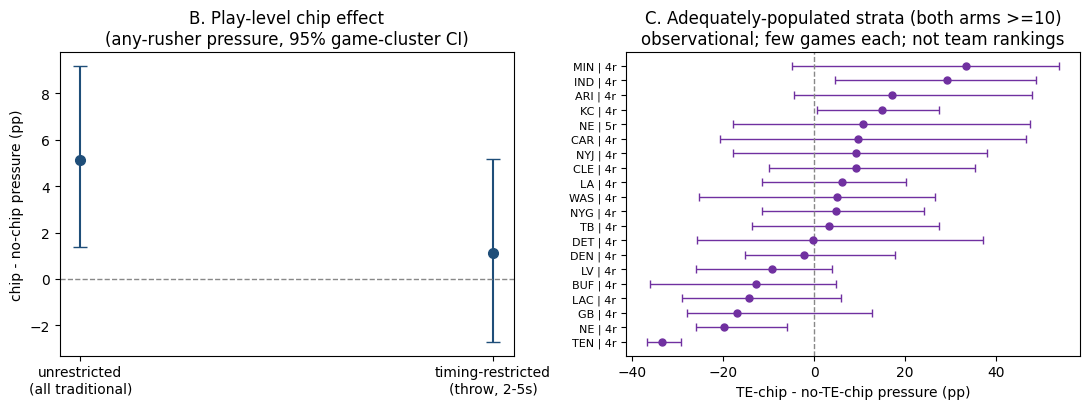

saved figure: C:\Users\isaac\CodingProjects\NYUDataBowl\figures\chip_timing_refinement.png


In [26]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))

# left: play-level chip-minus-nochip, unrestricted vs timing-restricted
labels = ['unrestricted\n(all traditional)', 'timing-restricted\n(throw, 2-5s)']
ests = [B_unrestricted['diff_pp'], B_restricted['diff_pp']]
los  = [B_unrestricted['ci_low'],  B_restricted['ci_low']]
his  = [B_unrestricted['ci_high'], B_restricted['ci_high']]
yerr = [[e - lo for e, lo in zip(ests, los)], [hi - e for e, hi in zip(ests, his)]]
ax1.errorbar(range(len(ests)), ests, yerr=yerr, fmt='o', color='#1f4e79',
             capsize=5, markersize=7)
ax1.axhline(0, color='#888', lw=1, ls='--')
ax1.set_xticks(range(len(labels))); ax1.set_xticklabels(labels)
ax1.set_ylabel('chip - no-chip pressure (pp)')
ax1.set_title('B. Play-level chip effect\n(any-rusher pressure, 95% game-cluster CI)')

# right: adequately-populated TE-chip strata diffs (team | rusher count), with CIs
adq = adequate.sort_values('te_minus_no_te_pp').reset_index(drop=True)
y = range(len(adq))
xl = (adq['te_minus_no_te_pp'] - adq['ci_low']).to_numpy()
xh = (adq['ci_high'] - adq['te_minus_no_te_pp']).to_numpy()
ax2.errorbar(adq['te_minus_no_te_pp'], y, xerr=[xl, xh], fmt='o', color='#7030a0',
             capsize=3, markersize=5, lw=1)
ax2.axvline(0, color='#888', lw=1, ls='--')
ax2.set_yticks(list(y))
ax2.set_yticklabels([f"{t} | {n}r" for t, n in zip(adq['team'], adq['n_rushers'])], fontsize=8)
ax2.set_xlabel('TE-chip - no-TE-chip pressure (pp)')
ax2.set_title(f'C. Adequately-populated strata (both arms >={SPARSE})\n'
              'observational; few games each; not team rankings')

plt.tight_layout()
fig_out = ROOT / 'figures' / 'chip_timing_refinement.png'
fig_out.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(fig_out, dpi=120)
plt.show()
print('saved figure:', fig_out)

### Verification / notebook checks

In [27]:
# one row per play; source-table agreement; partition checks
print('one row per play (play_tbl):', play_tbl.duplicated(['gameId','playId']).sum() == 0)
print('one row per timing record   :', timing.duplicated(['gameId','playId']).sum() == 0)
print('route-level t_throw agreed within play (max spread 0):', float(spread.max()) == 0.0)
print('restricted keys subset of traditional plays:',
      restricted_keys <= set(map(tuple, trad_plays.to_numpy())))
_chk = cov[cov['in_window'] == True]
print('every in-window play has an actual-throw endpoint:', bool(_chk['is_actual_throw'].all()))
print('every in-window t_throw within [2,5]:', bool(_chk['t_throw'].between(2,5).all()))
print('strata play counts sum to restricted pop:',
      int((team_rusher['te_chip_n'] + team_rusher['no_te_chip_n']).sum()) == len(rpop))
print('missing-arm strata report NaN diff (never imputed 0):',
      bool(team_rusher.loc[~team_rusher['both_arms_present'], 'te_minus_no_te_pp'].isna().all()))
print('overlap partition holds (no_te = rbfb-overlap + no-qualifying):',
      int((~rpop['te_chip']).sum()) == int(rpop['no_te_but_rbfb'].sum())
                                      + int(rpop['no_qualifying_chip'].sum()))
print('existing unrestricted play-level finding preserved (+5.12pp):',
      round(B_unrestricted['diff_pp'], 2) == 5.12)
print('within-rusher & stay-or-go sections above untouched (this section only appends).')

one row per play (play_tbl): True
one row per timing record   : True
route-level t_throw agreed within play (max spread 0): True
restricted keys subset of traditional plays: True
every in-window play has an actual-throw endpoint: True
every in-window t_throw within [2,5]: True
strata play counts sum to restricted pop: True
missing-arm strata report NaN diff (never imputed 0): True
overlap partition holds (no_te = rbfb-overlap + no-qualifying): True
existing unrestricted play-level finding preserved (+5.12pp): True
within-rusher & stay-or-go sections above untouched (this section only appends).


### What a coach can — and cannot — infer

These are **observational comparisons**, not causal estimates.

- **Matching team and exact rusher count does not control** personnel, protection design, down/distance, route concept, or opponent quality. Chipping is not assigned at random.
- **Conditioning on an actual throw in the 2–5 s window excludes sacks and scrambles**, and can **select plays on the consequences of protection** (a play ends in a sack precisely when protection fails). The restricted population is therefore a *conditioned* slice, not a random subset — a reason the timing-restricted chip effect (**~+1 pp, CI crossing 0**) is smaller than the unrestricted one (**+5.12 pp**).
- These results **cannot establish overall protection effectiveness** or whether chipping *causes* a pressure change.
- The team × rusher-count strata are **small and rest on very few games** (≤17 per team; every adequately-populated stratum draws from fewer than 10 games, so `few_games_flag` is set throughout). We report counts, rates, differences, and CIs; we **do not** rank teams or highlight isolated significant strata across the many comparisons. A **missing arm** means the difference is **unavailable**, not zero.
- `end_event` handling depends on treating `autoevent_passforward` as an actual throw (Sid's `PASS_FORWARD_FALLBACK`); this remains a confirmation item for Sid, noted in the handoff follow-ups above.